![Logo](LogoCab.png)

# Introduction and Project Context

Amazing Creative Desk Coworking (ACDC) operates in a competitive coworking market with a diverse member base, where customers can differ considerably in terms of their membership plans, usage patterns, and engagement with the available services. Understanding these differences is important for identifying distinct customer groups and developing strategies that better respond to their needs.

This project focuses on the analysis of ACDC’s membership and space-usage data collected over a three-year period. By exploring customer characteristics, membership information, and behavioural patterns, the aim is to identify meaningful segments within the customer base. These insights can then be used to support a more targeted marketing strategy, helping ACDC improve customer satisfaction, retention, and overall business performance.

The analysis follows a data-driven approach to customer segmentation, considering different perspectives such as customer value and usage behaviour. The results of this analysis will provide the basis for the subsequent clustering process and the development of actionable business recommendations.

# Importing Libraries

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import sqlite3
import os
from math import ceil, floor
from math import radians, sin, cos, sqrt, atan2
from sklearn.experimental import enable_iterative_imputer 
from sklearn.impute import IterativeImputer
from itertools import combinations
import scipy.stats as ss
from sklearn.preprocessing import RobustScaler
from IPython.display import HTML, display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# For better resolution plots
%config InlineBackend.figure_format = 'retina' 

# Set theme for seaborn
sns.set_theme(style="whitegrid")

# Import Dataset

In this section, we load the coworking dataset from the CSV file using semicolons as column separators. We also perform an initial data quality check to identify and remove any duplicate records, ensuring that each member entry is unique before proceeding with the exploratory data analysis and modeling phases.

In [2]:
dataset = pd.read_csv("../data/acdc_dataset.csv",sep = ";", index_col= 'member_id')

# Metadata

In this section, we outline the variables included in the ACDC dataset. A clear understanding of the definition, type, and nature of each attribute is crucial for correctly interpreting customer behaviors, guiding feature engineering, and supporting the subsequent segmentation process.
This information is taken directly from the annex of the guidelines document.

In [3]:
metadata_dict = {
    "member_id": "Unique identifier of each member",
    "age": "Age of the member at the extraction date",
    "gender": "Gender of the member",
    "country": "The country where the member (or their associated company) is based",
    "industry": "The industry sector the member works in",
    "is_team_account": "Whether the membership is held by a team/company account rather than an individual",
    "n_colleagues_on_account": "Number of colleagues sharing the account",
    "plan_tier": "Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)",
    "plan_days_per_week": "Number of days per week the member's plan entitles them to use the space",
    "membership_start": "Date the membership first began",
    "membership_end": "Date the membership first ended",
    "last_badge_swipe": "Date of the member's most recent physical entry to the space",
    "days_since_last_visit": "Number of days since the member's last recorded visit",
    "total_visits": "Total number of visits the member made over the whole membership",
    "avg_weekly_visits": "Average number of visits per week over the membership",
    "entitled_visits_last_period": "Number of visits the member's plan entitled them to during the last period of their membership",
    "actual_visits_last_period": "Number of visits the member actually made during the last period of their membership",
    "meeting_room_hours": "Hours of meeting-room usage recorded for the member",
    "event_space_hours": "Hours of event-space usage recorded for the member",
    "guest_passes_issued": "Number of guest passes the member issued",
    "uses_meeting_rooms": "Whether the member ever used the meeting-room add-on",
    "uses_event_space": "Whether the member ever used the event-space add-on",
    "uses_guest_passes": "Whether the member ever used the guest-pass add-on",
    "uses_print": "Whether the member used the print add-on",
    "uses_mail_handling": "Whether the member used the mail-handling add-on",
    "uses_phone_booths": "Whether the member used the phone-booth add-on",
    "uses_day_passes": "Whether the member used the day-pass add-on",
    "uses_storage": "Whether the member used the storage add-on",
    "uses_bike_locker": "Whether the member used the bike-locker add-on",
    "n_renewals": "Number of times the membership was renewed",
    "lifetime_value": "Total revenue attributed to the member over the whole membership"
}

# convert the metadata dictionary to a DataFrame for better visualization
df_meta = pd.DataFrame(list(metadata_dict.items()), columns=["Variable", "Description"]).set_index("Variable")

# Set pandas display options to show all rows and columns without truncation
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)

df_meta

,Description
Variable,
member_id,Unique identifier of each member
age,Age of the member at the extraction date
gender,Gender of the member
country,The country where the member (or their associated company) is based
industry,The industry sector the member works in
is_team_account,Whether the membership is held by a team/company account rather than an individual
n_colleagues_on_account,Number of colleagues sharing the account
plan_tier,Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office)
plan_days_per_week,Number of days per week the member's plan entitles them to use the space


# General Look at the DataSet

In [4]:
print('Dataset shape:', dataset.shape)

Dataset shape: (15465, 30)


In [5]:
dataset.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74


In [6]:
dataset.tail()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,2023-07-01,2023-06-28,3,74,2.55,26.09,21,0.0,0.0,0.0,False,False,False,1,True,True,False,False,False,0,1422.36
CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,2023-10-06,2023-10-04,2,407,3.71,43.48,31,30.1,17.6,0.0,True,True,False,1,False,True,True,True,False,4,11834.5
CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,2022-04-19,2022-02-12,66,5,0.45,26.09,4,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,435.82


In [7]:
dataset.columns

Index(['age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='str')

# Data Quality Check

In [8]:
df_meta["Data Type"] = dataset.dtypes
df_meta

,Description,Data Type
Variable,,
member_id,Unique identifier of each member,NaN
age,Age of the member at the extraction date,float64
gender,Gender of the member,str
country,The country where the member (or their associated company) is based,str
industry,The industry sector the member works in,str
is_team_account,Whether the membership is held by a team/company account rather than an individual,bool
n_colleagues_on_account,Number of colleagues sharing the account,int64
plan_tier,Current membership tier (hot_desk < flex < dedicated_desk < full_time < private_office),str
plan_days_per_week,Number of days per week the member's plan entitles them to use the space,int64


In [9]:
dataset.info()

<class 'pandas.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  str    
 2   industry                     15465 non-null  str    
 3   country                      15035 non-null  str    
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  str    
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  str    
 9   membership_end               15465 non-null  str    
 10  last_badge_swipe             15465 non-null  str    
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_visits     

In this section, we review the data types (`dtypes`) of each feature to ensure they are correctly formatted for subsequent exploratory analysis and clustering algorithms. Based on our structural inspection (`df.info()`), several discrepancies and necessary type conversions have been identified:

`member_id` isn't listed here because it became the index

date variables (`membership_ends`, `membership_starts` and `last_badge_swipe`) are currently cast as String(`object`) but should be cast to `dateTime`.

`age` and `guest_passes_issued` are currently stored as float64 due to the presence of missing values. Since both represent a discrete value,  these variables should be converted to integer (`int`) after handling the missing values.

`entitled_visits_last_period` represents the "number of visits the member's plan entitled them to during the last period of their membership" and this intuitively seems like it should be stored as an `int` but it is stored as a `float`, this needs further looking into. The hypothesis is that it is a calculated number from other variables.

`uses_print` represents binary usage but is currently stored as numeric integer (`int64`). It should be cast to boolean (`bool`) to match the other binary flags in the dataset (e.g., `uses_meeting_rooms`, `uses_phone_booths`).

Lifetime Value (`lifetime_value`): Currently stored as an object (`string`) instead of a numeric type. This hints at the presence of formatting characters (such as currency symbols or spaces) that must be cleaned, parsed, and converted to `float` to correctly measure the economic contribution of each member.

In [10]:
temp_df = dataset.copy()
temp_df.drop(columns=["uses_print"]).describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


The descriptive statistics (`df.describe()`) reveal several interesting patterns alongside notable data quality anomalies that require careful consideration. Specifically, we observe extreme values and physically impossible entries (such as negative numbers in visits, renewal counts, and meeting room hours, as well as outliers like an age of 149 years).

Furthermore, a large proportion of members show low space utilization compared to their plan entitlements. These preliminary findings highlight the need for targeted data cleaning and deeper behavioral investigation before defining our final customer segmentation strategy.

In [11]:
dataset.describe(include='object').T

/tmp/ipykernel_395/800502257.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  dataset.describe(include='object').T


,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


This descriptive statistic for the `object` types shows us that we have 12 unique genders which might be errors or different ways of writing like "Female", "female", "fem", "f" , " female", this needs to be confirmed and fixed. Most customers are from Portugal.

We have 3956 members which membership has ended 50 years ago, this is either an error and needs to be fixed or the default "zero" date that systems write when the field is empty or in other words "no end date yet"

We can also confirm lifetime value(`lifetime_value`) is a numeric value due to the proportion of uniques, we can also see 1725 members have a membership but haven't made spent anything (the lifetime_value is `0`) which can mean that they just started their membership, this needs further looking into.

In [12]:
summary = pd.DataFrame({
    "Non-null values": dataset.count(),
    "Unique values": dataset.nunique(),
    "Missing count": dataset.isnull().sum(),
    "Missing %": dataset.isnull().mean() * 100,
    "Negative values": (dataset.select_dtypes(include=[np.number]) < 0).sum(),
})

summary

,Non-null values,Unique values,Missing count,Missing %,Negative values
actual_visits_last_period,15465,61,0,0.000000,0.0
age,14907,84,558,3.608147,0.0
avg_weekly_visits,15465,616,0,0.000000,0.0
country,15035,33,430,2.780472,NaN
days_since_last_visit,15465,430,0,0.000000,56.0
entitled_visits_last_period,15465,1876,0,0.000000,0.0
event_space_hours,15465,824,0,0.000000,8.0
gender,14935,12,530,3.427093,NaN
guest_passes_issued,14194,205,1271,8.218558,7.0
industry,15465,43,0,0.000000,NaN


The table above tells us how many unique values, how many missing and, if numeric, how many negatives each feature has. We have to keep in mind that there might be missing values in other forms for example a country that doesnt exist.

# Deeper Analysis

## Unique

In [13]:
for column in dataset.columns:
    unique_values = dataset[column].unique()
    print(f"Unique values on the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

Unique values on the column 'age': [ 38.  43.  45.  39.  23.  33.  30.  44.  37. 131.  20.  40.  32.  21.
  29.  25.  28.  51.  41.  nan  31.  42.  34.  36.  50.  24.  19.  47.
  54.  26.  53.  27.  46.  18.  48.  63.  35.  22.  59.  49.   4.   3.
  58.  72.   9.   8.  57.  52.  73. 132.  60.  55. 144.  61.   1.   6.
 141.   2.   7. 137.  66. 147. 140. 142.  56.  62. 145.   5.  65.  83.
  14. 138. 136. 146. 134.  70.  74.  93.  92. 143. 139.  91.  64. 149.
 135.]
-----------------------------------

Unique values on the column 'gender': <StringArray>
[ 'Female',    'Male',       'F',   'Other',       nan, ' Female',       'M',
    'male',   ' Male',   'other',  ' Other',  'female',       'O']
Length: 13, dtype: str
-----------------------------------

Unique values on the column 'industry': <StringArray>
['Information Technology',              'Education',                  'Legal',
                 'Health',                'Unknown',                  'Other',
             'Consulting',

Here we can see that the date columns have two distinct formats being used at the same time, `YYYY-MM-DD` and `DD/MM/YYYY`. This can be due to different nationalities using different date time formats, either way all need to be in the same format.

In the `plan_tier` we can see "HOT_DESK", "hot_desk", "hot desk", "hotdesk" which all refer to the same, this happens in almost every other String column line Portugal, portugal, PT in country, in industry the same also happens etc so we can confirm the uniques are overinflated and that the 12 genders are indeed a mistake and that there should be 3, female, male and other.

In `age` we also see that there are some questionable numbers like minors from age 1 to 14 and people aged 120+.

## Values Count

In [14]:
for column in dataset.columns:
    unique_values = dataset[column].value_counts()
    print(f"The number of the distinct values in the column '{column}': {unique_values}")
    print('-----------------------------------')
    print('')

The number of the distinct values in the column 'age': age
34.0     710
31.0     679
32.0     658
36.0     655
35.0     650
33.0     647
38.0     637
37.0     626
30.0     619
29.0     597
39.0     588
40.0     546
28.0     528
41.0     516
42.0     474
27.0     450
26.0     449
43.0     422
25.0     420
24.0     372
44.0     357
23.0     333
45.0     303
22.0     290
21.0     269
46.0     250
47.0     242
20.0     214
48.0     187
49.0     175
19.0     169
50.0     124
51.0     109
52.0     105
53.0      80
18.0      73
54.0      64
55.0      36
4.0       26
3.0       26
56.0      26
58.0      25
57.0      22
59.0      14
9.0       11
61.0      11
60.0      10
141.0      9
2.0        8
7.0        8
131.0      7
63.0       7
8.0        6
6.0        6
62.0       5
140.0      4
5.0        4
83.0       4
134.0      4
72.0       3
132.0      3
66.0       3
135.0      3
144.0      2
1.0        2
142.0      2
65.0       2
136.0      2
146.0      2
93.0       2
64.0       2
73.0       1
137.0

The number of the distinct values in the column 'total_visits': total_visits
 5       652
 7       594
 4       589
 3       568
 6       552
 8       501
 9       456
 2       418
 10      356
 1       310
 11      281
 12      249
 13      189
 14      182
 15      139
 16      126
 17      125
 25      122
 18      120
 26      117
 0       109
 24      105
 20       90
 19       88
 35       81
 22       73
 21       72
 29       67
 23       66
 38       63
 37       61
 42       60
 31       60
 27       59
 43       59
 28       57
 36       57
 74       57
 32       57
 39       55
 33       53
 75       51
 40       50
 101      49
 85       49
 34       49
 41       48
 69       48
 76       48
 30       48
 45       47
 88       47
 61       47
 71       45
 46       45
 127      45
 64       45
 44       45
 94       44
 63       44
 49       44
 91       44
 58       44
 89       44
 93       43
 103      43
 68       43
 55       43
 70       43
 52       43
 122      43


The number of the distinct values in the column 'lifetime_value': lifetime_value
0               1725
360               37
6475.56           18
0.00 €            18
24283.37          18
7015.2            13
384               12
12                11
18                11
390               10
540               10
450               10
10612.73          10
4317.04            9
13131.01           9
7374.95            8
414                7
12591.38           7
570                6
13490.76           6
435                6
24571.17           6
564                5
10073.1            5
405                4
435.82             4
9253.03            4
7914.58            4
23743.74           4
24211.42           4
14390.14           4
25470.55           4
25182.75           4
4604.85            4
474                4
118.31             3
10432.85           3
10972.48           3
2184.6             3
10900.53           3
639                3
6835.32            3
381.96             3
351.63          

## Check Duplicates Values

In [15]:
#Check how many duplicates exist
print(f"number of duplicates: {dataset.duplicated().sum()}")

#check the percentage of duplicates in our DataFrame
print(f"percentage of duplicates: {dataset.duplicated().sum() / len(dataset) * 100:.2f}%")

print(f"number of duplicate indices: {dataset.index.duplicated().sum()}")

number of duplicates: 182
percentage of duplicates: 1.18%
number of duplicate indices: 15


With `member_id` as the index, `duplicated()` compares the 30 feature columns and finds 182 repeated rows. Checking the index separately shows 15 repeated IDs, all exact copies of an earlier row. The remaining 182-15=167 rows are identical to another member in every field, including dates and lifetime value, but have a different ID. They are most likely the same member registered twice. We remove all 182, keeping the first occurrence, so that no member counts twice in the clustering.

In [16]:
#we drop the duplicates from the DataFrame with index
dataset.drop_duplicates(inplace= True)

# Check that the duplicates were removed
dataset.duplicated().sum()

np.int64(0)

# Fixing Formats and Categories

Before plotting anything we sort out the formats. The same plan shows up as "HOT_DESK", "hotdesk" and "Hot Desk", the dates come in two different formats, and `lifetime_value` is stored as text. None of this changes what the data says, it only makes it readable, so it makes sense to do it first. Fixing the actual values (impossible ages, placeholders, negatives) is left for the cleaning section, after the plots.

In [17]:
dataset_raw = dataset.copy()  # keep a copy of the raw data for later comparison

In [18]:
# The file mixes two date formats (YYYY-MM-DD and DD/MM/YYYY), so each one is read with its own format.
# Using format='mixed' with dayfirst=True swaps day and month in the YYYY-MM-DD dates in recent pandas versions.
for column in ["membership_start", "membership_end", "last_badge_swipe"]:
    iso_dates = pd.to_datetime(dataset[column], format="%Y-%m-%d", errors="coerce")
    european_dates = pd.to_datetime(dataset[column], format="%d/%m/%Y", errors="coerce")
    dataset[column] = iso_dates.fillna(european_dates)

In [19]:
dataset["uses_print"] = dataset["uses_print"].astype(bool)

In [20]:
def normalize_country(value):
    if pd.isna(value):
        return value

    value = value.strip().lower()
    value = value.replace("-", " ").replace("_", " ")
    value = " ".join(value.split())

    countries = {
        # Portugal
        "pt": "portugal",
        "portucal": "portugal",

        # Germany
        "de": "germany",
        "deutschland": "germany",

        # United Kingdom
        "uk": "united kingdom",
        "u.k.": "united kingdom",
        "gb": "united kingdom",

        # Ireland
        "ie": "ireland",

        # Spain
        "es": "spain",
        "españa": "spain",
        "espana": "spain",

        # Netherlands
        "nl": "netherlands",
        "the netherlands": "netherlands",
        "holland": "netherlands",

        # France
        "fr": "france",

        # Other
        "other (europe)": "other (europe)"
    }

    return countries.get(value, value)

In [21]:
def normalize_gender(value):
    if pd.isna(value):
        return value

    value = value.strip().lower()

    mapping = {
        "f": "female",
        "m": "male",
        "o": "other"
    }

    return mapping.get(value, value)

In [22]:
def normalize_industry(value):
    if pd.isna(value):
        return value

    value = value.strip().lower()
    value = " ".join(value.replace("-", " ").split())

    mapping = {
        "it": "information technology",
        "tech": "information technology",

        "marketing and pr": "marketing & pr",
        "marketing/pr": "marketing & pr",

        "design and creative": "design & creative",
        "design/creative": "design & creative",

        "realestate": "real estate",
    }

    return mapping.get(value, value)

In [23]:
def normalize_plan_tier(value):
    if pd.isna(value):
        return value

    value = value.strip().lower()
    value = value.replace("_", "").replace(" ", "").replace("-", "")

    mapping = {
        "hotdesk": "hot desk",
        "dedicateddesk": "dedicated desk",
        "fulltime": "full time",
        "privateoffice": "private office",
    }

    return mapping.get(value, value)

In [24]:
dataset["country"] = dataset["country"].apply(normalize_country)
dataset["gender"] = dataset["gender"].apply(normalize_gender)
dataset["industry"] = dataset["industry"].apply(normalize_industry)
dataset["plan_tier"] = dataset["plan_tier"].apply(normalize_plan_tier)

In [25]:
dataset["lifetime_value"] = pd.to_numeric(dataset["lifetime_value"].str.replace(",", "").str.replace("€", "").str.strip(), errors='coerce')

In [26]:
# Quick check that each category now has a single spelling
for column in ["plan_tier", "gender", "country", "industry"]:
    print(f"{column}: {sorted(dataset[column].dropna().unique())}\n")

plan_tier: ['dedicated desk', 'flex', 'full time', 'hot desk', 'private office']

gender: ['female', 'male', 'other']

country: ['france', 'germany', 'ireland', 'netherlands', 'other (europe)', 'portugal', 'spain', 'united kingdom']

industry: ['consulting', 'design & creative', 'education', 'finance', 'health', 'information technology', 'legal', 'marketing & pr', 'other', 'real estate', 'unknown']



# Exploratory Visualisations

We start with the distribution of each numeric variable, mostly to spot problems. Then we cross variables with each other to see what kind of members are behind the numbers. The values are not cleaned yet, so every chart simply leaves out the values we already know are impossible.

In [27]:
# Colours kept consistent with the rest of the project
MAIN_COLOR = "#0062FF"
TIER_ORDER = ["hot desk", "flex", "dedicated desk", "full time", "private office"]
TIER_COLORS = dict(zip(TIER_ORDER, ["#c6dbef", "#9ecae1", "#6baed6", "#3182bd", "#08519c"]))   # light = cheaper plan, dark = premium

## Distributions

With the formats fixed, but before cleaning the values, we look at the distribution of each numeric variable. The goal at this stage is to find problems in the data (placeholders, impossible values and extreme values) and to understand the shape of each variable. The same plots will be repeated after the cleaning step, to confirm the cleaning worked and to interpret the members' profiles.

The y-axis of the histograms uses a **log scale**: most variables have bars with thousands of members next to values held by only a handful of members, and on a normal scale those rare values would be invisible. Whole-number variables with a limited range (e.g. `age`, `plan_days_per_week`) get one bar per value. `uses_print` is a 0/1 flag, so it is not plotted here, and `lifetime_value` is looked at further down, split by plan.

In [28]:
def plot_histograms(df, features, title, discrete_features=(), log_counts=True, n_cols=3):
    """Plot one histogram per feature in a grid with n_cols columns."""
    n_rows = ceil(len(features) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows), layout="constrained", squeeze=False)
    axes = axes.flatten()

    for i, (ax, feature) in enumerate(zip(axes, features)):
        # Whole-number variables get one bar per value; the others are split into 20 bins
        sns.histplot(data=df, x=feature, bins=20, discrete=feature in discrete_features, ax=ax,
                     color=MAIN_COLOR, edgecolor="black", alpha=1)

        y_label = "Members"
        if log_counts:
            ax.set_yscale("log")      # keeps values held by only a few members visible
            y_label += " (log scale)"

        ax.set_title(feature, fontsize=13)
        ax.set_xlabel("")
        ax.set_ylabel(y_label if i % n_cols == 0 else "")   # y label only on the first column

    # Hide the empty panels left in the grid
    for ax in axes[len(features):]:
        ax.set_visible(False)

    fig.suptitle(title, fontsize=16)
    plt.show()

### Histograms - Descriptive Statistics and Numerical Distributions

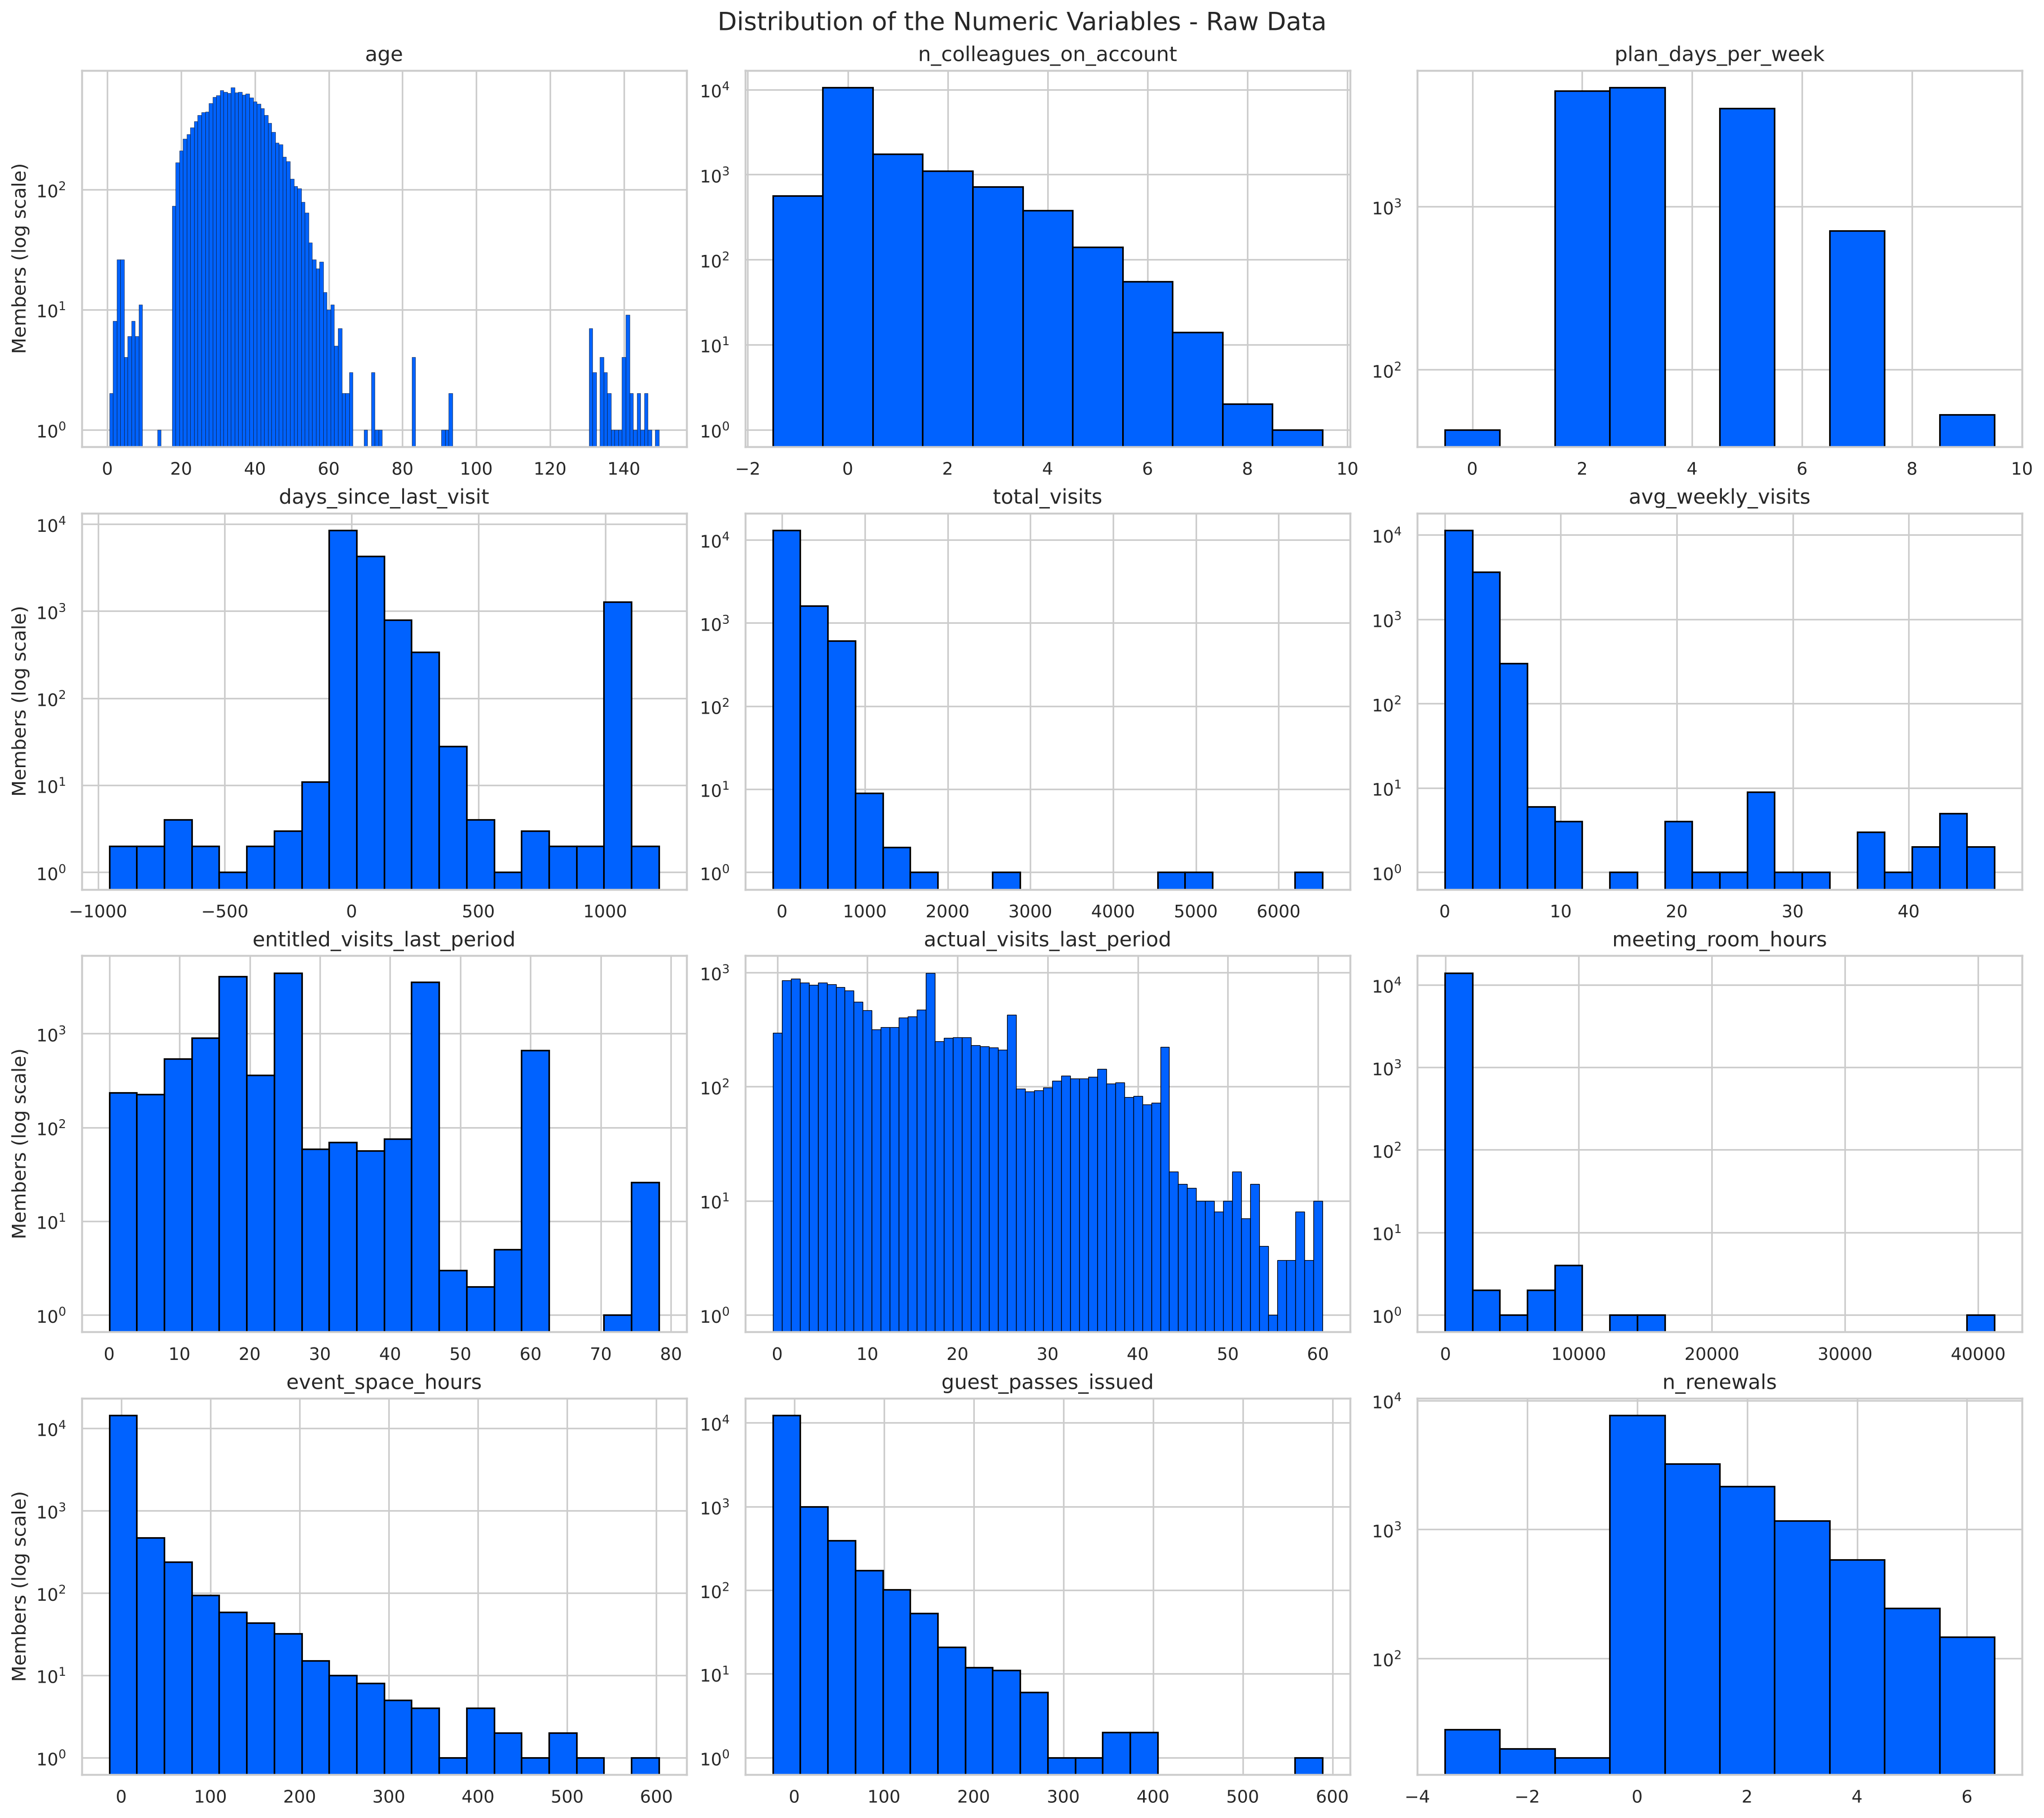

In [29]:
# Numeric variables to plot
numeric_features = [
    'age',
    'n_colleagues_on_account',
    'plan_days_per_week',
    'days_since_last_visit',
    'total_visits',
    'avg_weekly_visits',
    'entitled_visits_last_period',
    'actual_visits_last_period',
    'meeting_room_hours',
    'event_space_hours',
    'guest_passes_issued',
    'n_renewals'
]

# Whole-number variables with a limited range, plotted with one bar per value
discrete_features = ['age', 'n_colleagues_on_account', 'plan_days_per_week', 'actual_visits_last_period', 'n_renewals']

plot_histograms(dataset, numeric_features, "Distribution of the Numeric Variables - Raw Data", discrete_features)

In [30]:
# Shape of each distribution:
# - Skewness: 0 = symmetric, above 1 = strongly right-skewed (long tail of high values)
# - Zeros (%): share of zeros among the recorded (non-missing) values
distribution_summary = pd.DataFrame({
    "Skewness": dataset[numeric_features].skew(),
    "Zeros (%)": (dataset[numeric_features] == 0).sum() / dataset[numeric_features].notna().sum() * 100
})

distribution_summary.round(2)

,Skewness,Zeros (%)
age,3.04,0.00
n_colleagues_on_account,2.12,69.12
plan_days_per_week,0.93,0.28
days_since_last_visit,2.72,0.55
total_visits,6.86,0.70
avg_weekly_visits,10.24,0.09
entitled_visits_last_period,0.73,0.07
actual_visits_last_period,1.06,1.92
meeting_room_hours,70.43,65.20
event_space_hours,9.18,88.50


In [31]:
# Members affected by each problem seen in the histograms
data_problems = {
    "age below 18": (dataset["age"] < 18).sum(),
    "age above 100": (dataset["age"] > 100).sum(),
    "n_colleagues_on_account = -1": (dataset["n_colleagues_on_account"] == -1).sum(),
    "plan_days_per_week not 2, 3, 5 or 7": (~dataset["plan_days_per_week"].isin([2, 3, 5, 7])).sum(),
    "days_since_last_visit = 999": (dataset["days_since_last_visit"] == 999).sum(),
    "days_since_last_visit below 0": (dataset["days_since_last_visit"] < 0).sum(),
    "total_visits above 1,100": (dataset["total_visits"] > 1100).sum(),       # more visits than days in the 3-year period
    "avg_weekly_visits above 7": (dataset["avg_weekly_visits"] > 7).sum(),    # more than one visit per day
    "meeting_room_hours above 1,000": (dataset["meeting_room_hours"] > 1000).sum(),
}

# Negative values are impossible for counts and hours
for column in ["total_visits", "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals"]:
    data_problems[f"{column} below 0"] = (dataset[column] < 0).sum()

# Without the impossible ages, age is almost symmetric
age_valid = dataset.loc[dataset["age"].between(18, 100), "age"]
print(f"Skewness of age between 18 and 100: {age_valid.skew():.2f}")

pd.Series(data_problems, name="Members").to_frame()

Skewness of age between 18 and 100: 0.44


,Members
age below 18,98
age above 100,45
n_colleagues_on_account = -1,562
"plan_days_per_week not 2, 3, 5 or 7",96
days_since_last_visit = 999,1280
days_since_last_visit below 0,56
"total_visits above 1,100",7
avg_weekly_visits above 7,41
"meeting_room_hours above 1,000",19
total_visits below 0,42


**What the histograms show (raw data):**

*Problems to fix in the cleaning step* (counts in the table above)
- `age`: most members are between 18 and 65, but there are two separate groups of impossible ages: 1–14 (98 members) and 131–149 (45 members). These alone make `age` look strongly skewed (skewness 3.04, against 0.44 for ages 18–100). The few members aged 66–93 are unusual but possible.
- `n_colleagues_on_account`: a bar at −1 (562 members), a placeholder rather than a real count.
- `plan_days_per_week`: besides the four plans (2, 3, 5 and 7 days), 96 members have 0 or 9 days, which match no plan.
- `days_since_last_visit`: a spike at 999 (1,280 members), which is a placeholder, and 56 negative values down to −956.
- Values far from the rest: 7 members with more than 1,100 `total_visits` (more visits than days in the 3-year period, up to 6,530), 41 members averaging more than 7 visits per week (more than one per day, up to 47.4) and 19 members with more than 1,000 `meeting_room_hours` (up to 41,220).
- Negative values, impossible for counts and hours, in `total_visits`, `meeting_room_hours`, `event_space_hours`, `guest_passes_issued` and `n_renewals`.

*Shape of the data*
- The service-usage variables are mostly zeros with a long tail: 65% of the recorded `meeting_room_hours`, 88.5% of `event_space_hours` and 82.5% of `guest_passes_issued` are 0. Most members never use these services, while a few use them a lot. In distance-based clustering, these few members would dominate unless the variables are transformed (e.g. log scale) or turned into used / not used flags.
- `entitled_visits_last_period` is concentrated in four spikes, at 17.39, 26.09, 43.48 and 60.87, which correspond to the 2-, 3-, 5- and 7-day plans. The small spike at about 78 matches 9 days × 8.7, the invalid 9-day plan, so that error is carried into this variable too. This supports our hypothesis that it is calculated from the plan.
- `actual_visits_last_period` has spikes at 17, 26, 43 and 60 visits, exactly the full entitlement of each plan rounded down. This suggests a group of members who use every day their plan allows, a first behavioural signal worth exploring.

## Relationships Between Variables

The histograms show each variable on its own. Here we put them side by side. A few things from the histograms are worth following up: `entitled_visits_last_period` has one spike per plan, so the plan seems to drive a lot; `actual_visits_last_period` piles up at the full entitlement of each plan, so some members come every day they can; the service variables are mostly zeros; and `days_since_last_visit` has a long tail of members who have not been in for a while.

The functions for these charts are defined once below, so we can run exactly the same charts again after the cleaning.

In [32]:
ADDON_COLUMNS = ["uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print", "uses_mail_handling",
                 "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker"]


def chart_view(df):
    """Copy of the data with the few helper columns the charts need. Works before and after the cleaning."""
    view = df.copy()
    view["plan_tier"] = pd.Categorical(view["plan_tier"], categories=TIER_ORDER, ordered=True)
    view["active"] = view["membership_end"].isna() | (view["membership_end"] == pd.Timestamp("1970-01-01"))
    # Share of the visits the plan allowed that were actually used (1 = came every day the plan allows)
    view["utilisation"] = (view["actual_visits_last_period"] / view["entitled_visits_last_period"]).where(view["entitled_visits_last_period"] > 0)
    view["recency"] = view["days_since_last_visit"].where(view["days_since_last_visit"].between(0, 998))   # leaves out 999 and negatives
    view["ltv_positive"] = view["lifetime_value"].where(view["lifetime_value"] > 0)                        # log scale needs values above 0
    return view


def bar_labels(ax, values, horizontal=True, fmt="{:.1f}%"):
    for pos, value in enumerate(values):
        if horizontal:
            ax.text(value + 0.5, pos, fmt.format(value), va="center", fontsize=9)
        else:
            ax.text(pos, value + 1, fmt.format(value), ha="center", fontsize=10)


def plot_category_shares(df, columns, title, n_cols=3):
    n_rows = ceil(len(columns) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.2 * n_rows), layout="constrained", squeeze=False)
    axes = axes.flatten()
    for ax, column in zip(axes, columns):
        shares = df[column].value_counts(normalize=True, dropna=False).sort_values() * 100
        labels = ["missing" if pd.isna(label) else str(label) for label in shares.index]
        ax.barh(labels, shares.values, color=MAIN_COLOR, edgecolor="black", height=0.6)
        bar_labels(ax, shares.values)
        ax.set_title(column, fontsize=13)
        ax.set_xlim(0, shares.max() * 1.18)
    for ax in axes[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(title, fontsize=16)
    plt.show()


def plot_addon_adoption(df):
    share = df[ADDON_COLUMNS].mean().sort_values() * 100
    share.index = share.index.str.replace("uses_", "").str.replace("_", " ")
    fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
    ax.barh(share.index, share.values, color=MAIN_COLOR, edgecolor="black", height=0.6)
    bar_labels(ax, share.values)
    ax.set_xlabel("Members who use the service (%)")
    ax.set_title("Adoption of each add-on service", fontsize=13)
    plt.show()
    n_used = df[ADDON_COLUMNS].sum(axis=1)
    return (n_used.value_counts(normalize=True).sort_index() * 100).round(1).to_frame("% of members").rename_axis("Add-ons used")


def plot_plan_overview(view):
    palette = [TIER_COLORS[t] for t in TIER_ORDER]
    box_style = dict(showfliers=False, width=0.55, linecolor="black", medianprops={"color": "black", "linewidth": 2})
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), layout="constrained")

    sns.boxplot(data=view, x="plan_tier", y="ltv_positive", order=TIER_ORDER, hue="plan_tier", palette=palette, legend=False, ax=axes[0], **box_style)
    axes[0].set_yscale("log")
    axes[0].set_title("Lifetime value per plan (€, log scale)", fontsize=13)

    active_share = view.groupby("plan_tier", observed=True)["active"].mean() * 100
    axes[1].bar(active_share.index.astype(str), active_share.values, color=palette, edgecolor="black", width=0.6)
    bar_labels(axes[1], active_share.values, horizontal=False, fmt="{:.0f}%")
    axes[1].set_title("Members still active (%)", fontsize=13)

    sns.boxplot(data=view, x="plan_tier", y="utilisation", order=TIER_ORDER, hue="plan_tier", palette=palette, legend=False, ax=axes[2], **box_style)
    axes[2].set_title("Share of entitled visits used (last period)", fontsize=13)

    for ax in axes:
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.tick_params(axis="x", labelrotation=20)
    plt.show()

    return view.groupby("plan_tier", observed=True).agg(
        members=("plan_tier", "size"),
        median_lifetime_value=("ltv_positive", "median"),
        active_pct=("active", lambda s: s.mean() * 100),
        median_utilisation=("utilisation", "median"),
        median_renewals=("n_renewals", lambda s: s[s >= 0].median()),
    ).round(2)


def plot_addons_by_plan(view):
    table = view.groupby("plan_tier", observed=True)[ADDON_COLUMNS].mean().T * 100
    table.index = table.index.str.replace("uses_", "").str.replace("_", " ")
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    sns.heatmap(table, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, linewidths=1, linecolor="white",
                cbar_kws={"label": "Members using the service (%)"}, ax=ax)
    ax.set_title("Add-on adoption per plan (%)", fontsize=13)
    ax.set_xlabel("")
    ax.set_ylabel("")
    plt.show()


def plot_usage_patterns(view):
    fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), layout="constrained")

    sns.histplot(view["utilisation"].clip(upper=1.2), bins=24, color=MAIN_COLOR, edgecolor="black", alpha=1, ax=axes[0])
    axes[0].axvline(1, color="#ff6666", linestyle="--", linewidth=1.5)
    axes[0].set_title("Share of entitled visits used in the last period", fontsize=13)
    axes[0].set_xlabel("Actual / entitled visits (1 = came every day the plan allows)")
    axes[0].set_ylabel("Members")

    active = view[view["active"] & view["avg_weekly_visits"].between(0, 7)]
    hb = axes[1].hexbin(active["avg_weekly_visits"], active["recency"].clip(upper=400), gridsize=35, cmap="Blues", mincnt=1, bins="log")
    fig.colorbar(hb, ax=axes[1], label="Members (log scale)")
    axes[1].set_title("Active members: visit frequency vs days since last visit", fontsize=13)
    axes[1].set_xlabel("Average weekly visits")
    axes[1].set_ylabel("Days since last visit (capped at 400)")
    plt.show()

    groups = pd.cut(view["utilisation"], [-0.01, 0.2, 0.8, np.inf], labels=["below 20%", "20-80%", "above 80%"])
    return (pd.crosstab(view["plan_tier"], groups, normalize="index") * 100).round(1)


def dormant_members(view, days=90):
    dormant = view["active"] & (view["recency"] > days)
    print(f"Active members: {view['active'].sum()}  |  no visit for more than {days} days: {dormant.sum()} ({dormant.sum() / view['active'].sum():.0%})")
    return (view.loc[dormant, "plan_tier"].value_counts(normalize=True) * 100).round(1).to_frame("% of dormant active members")


def plot_profile_vs_plan(view):
    palette = [TIER_COLORS[t] for t in TIER_ORDER]
    fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), layout="constrained", gridspec_kw={"width_ratios": [1.6, 1]})

    by_industry = pd.crosstab(view["industry"], view["plan_tier"], normalize="index") * 100
    by_industry = by_industry.loc[by_industry[["dedicated desk", "full time", "private office"]].sum(axis=1).sort_values().index]
    by_industry.plot(kind="barh", stacked=True, color=palette, edgecolor="black", linewidth=0.5, width=0.7, ax=axes[0])
    axes[0].set_title("Plan mix per industry (% of members)", fontsize=13)
    axes[0].set_xlabel("% of members")
    axes[0].set_ylabel("")
    axes[0].legend(title="Plan tier", bbox_to_anchor=(1, 1), frameon=False)

    age_groups = pd.cut(view["age"], [17, 25, 35, 45, 100], labels=["18-25", "26-35", "36-45", "46-100"])   # impossible ages left out
    by_age = pd.crosstab(age_groups, view["plan_tier"], normalize="index") * 100
    by_age.plot(kind="bar", stacked=True, color=palette, edgecolor="black", linewidth=0.5, width=0.6, legend=False, ax=axes[1])
    axes[1].set_title("Plan mix per age group (% of members)", fontsize=13)
    axes[1].set_xlabel("Age group")
    axes[1].tick_params(axis="x", labelrotation=0)
    plt.show()

    return pd.crosstab(view["plan_tier"], view["is_team_account"], normalize="index").mul(100).round(1)

In [33]:
eda_before = chart_view(dataset)

### Categorical Variables

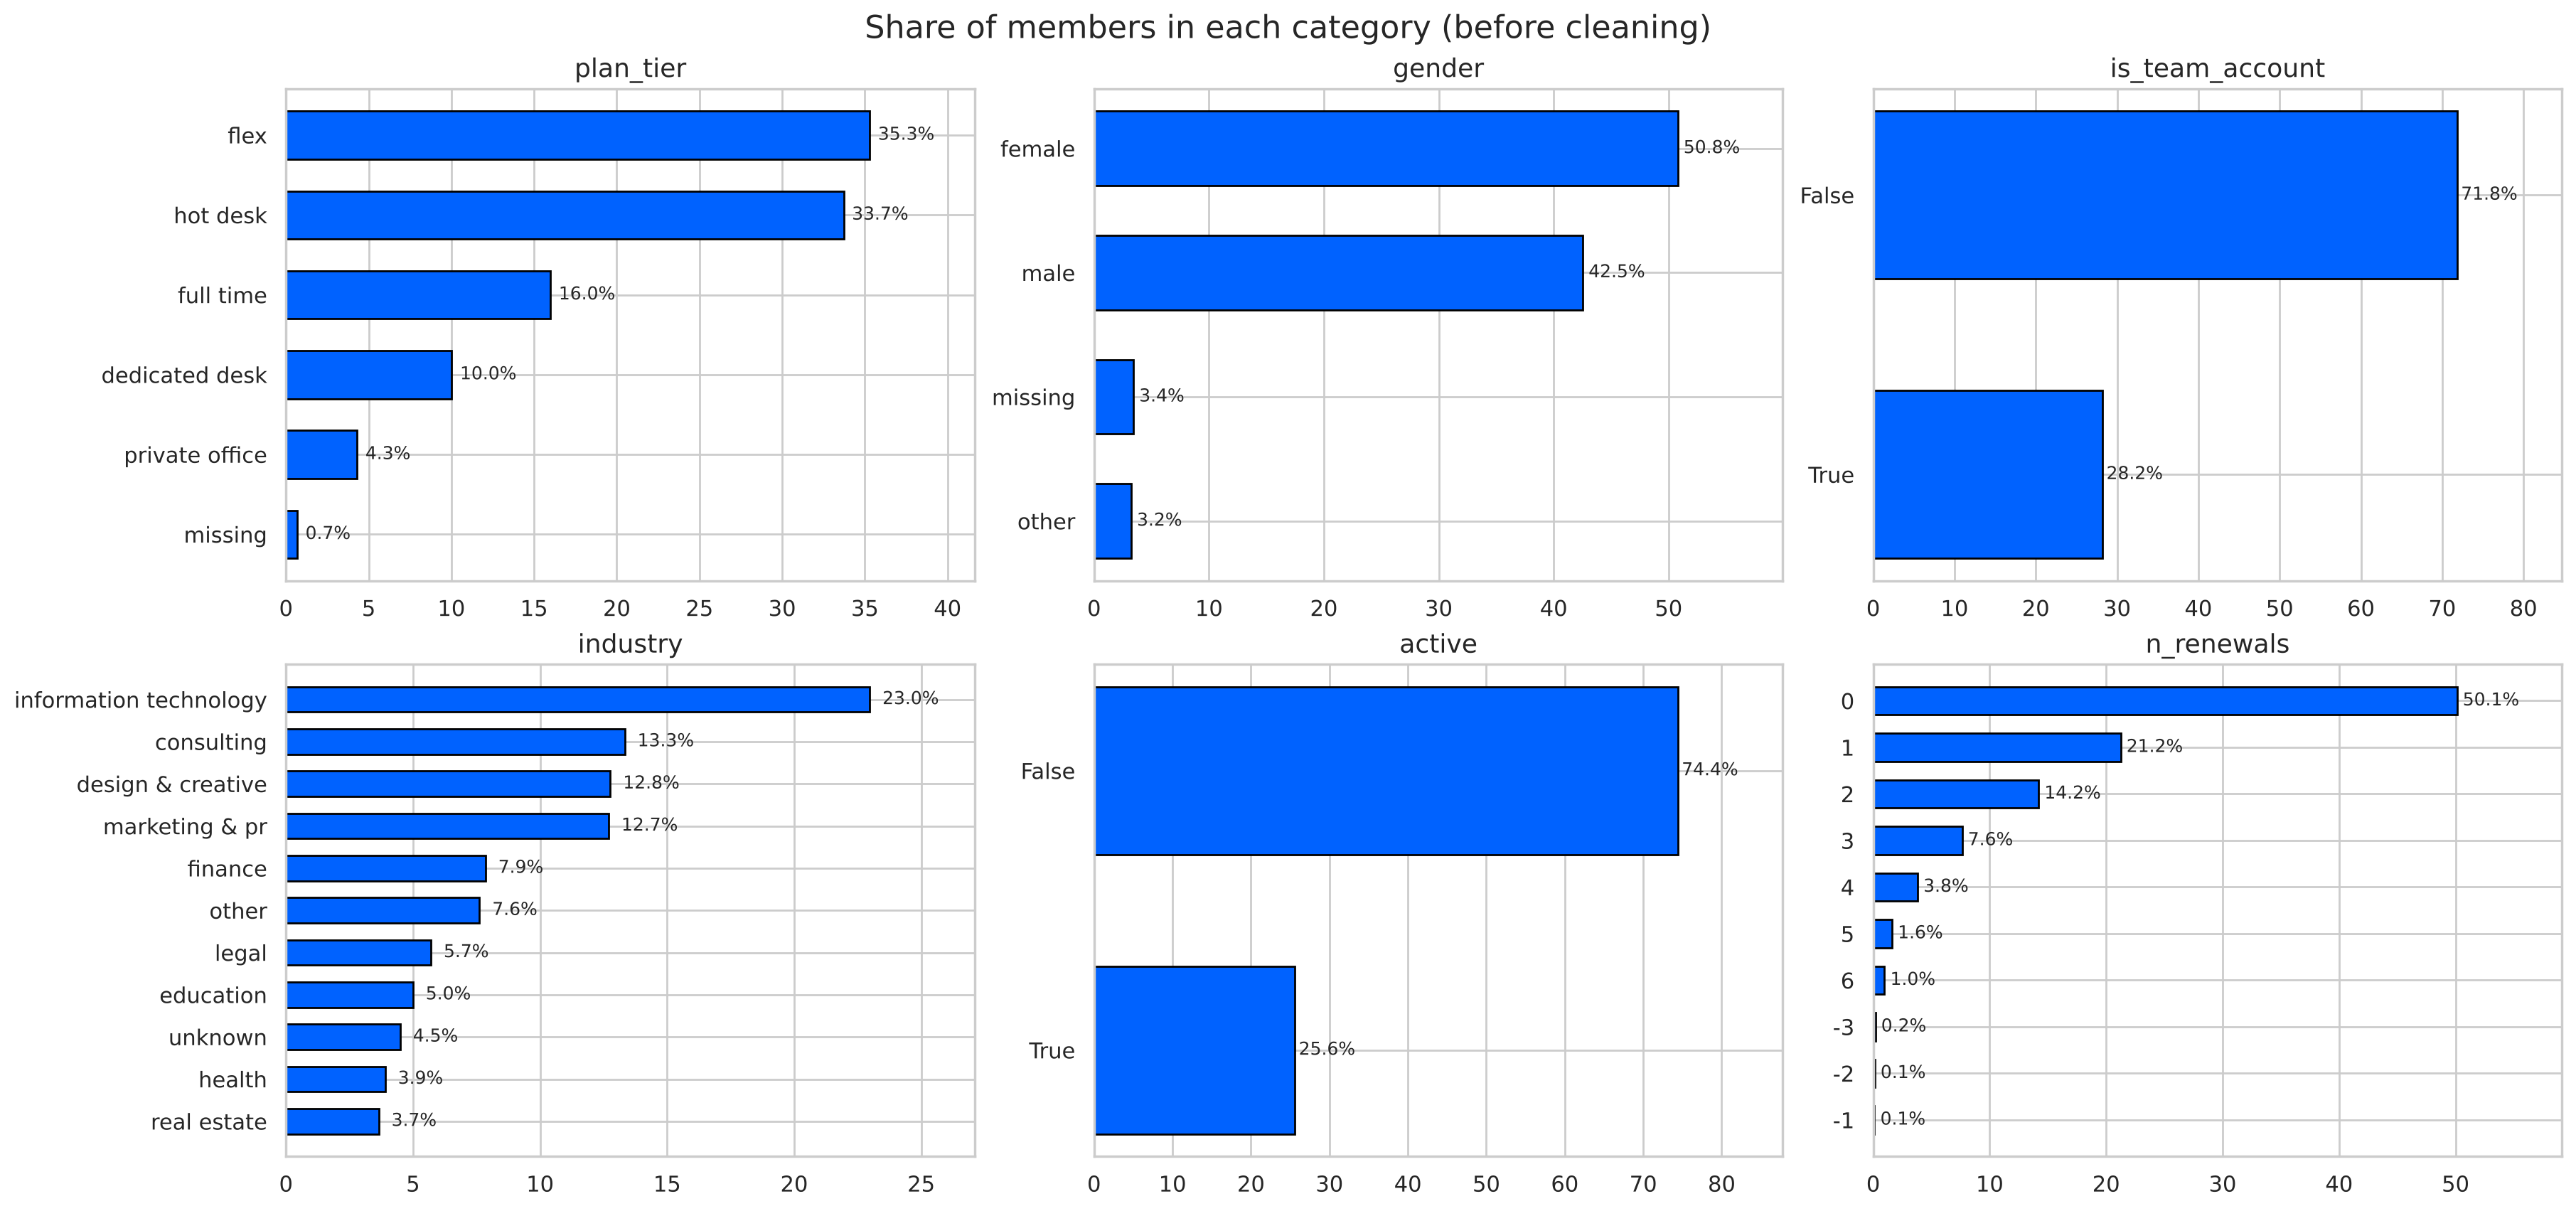

In [34]:
plot_category_shares(eda_before, ["plan_tier", "gender", "is_team_account", "industry", "active", "n_renewals"],
                     "Share of members in each category (before cleaning)")

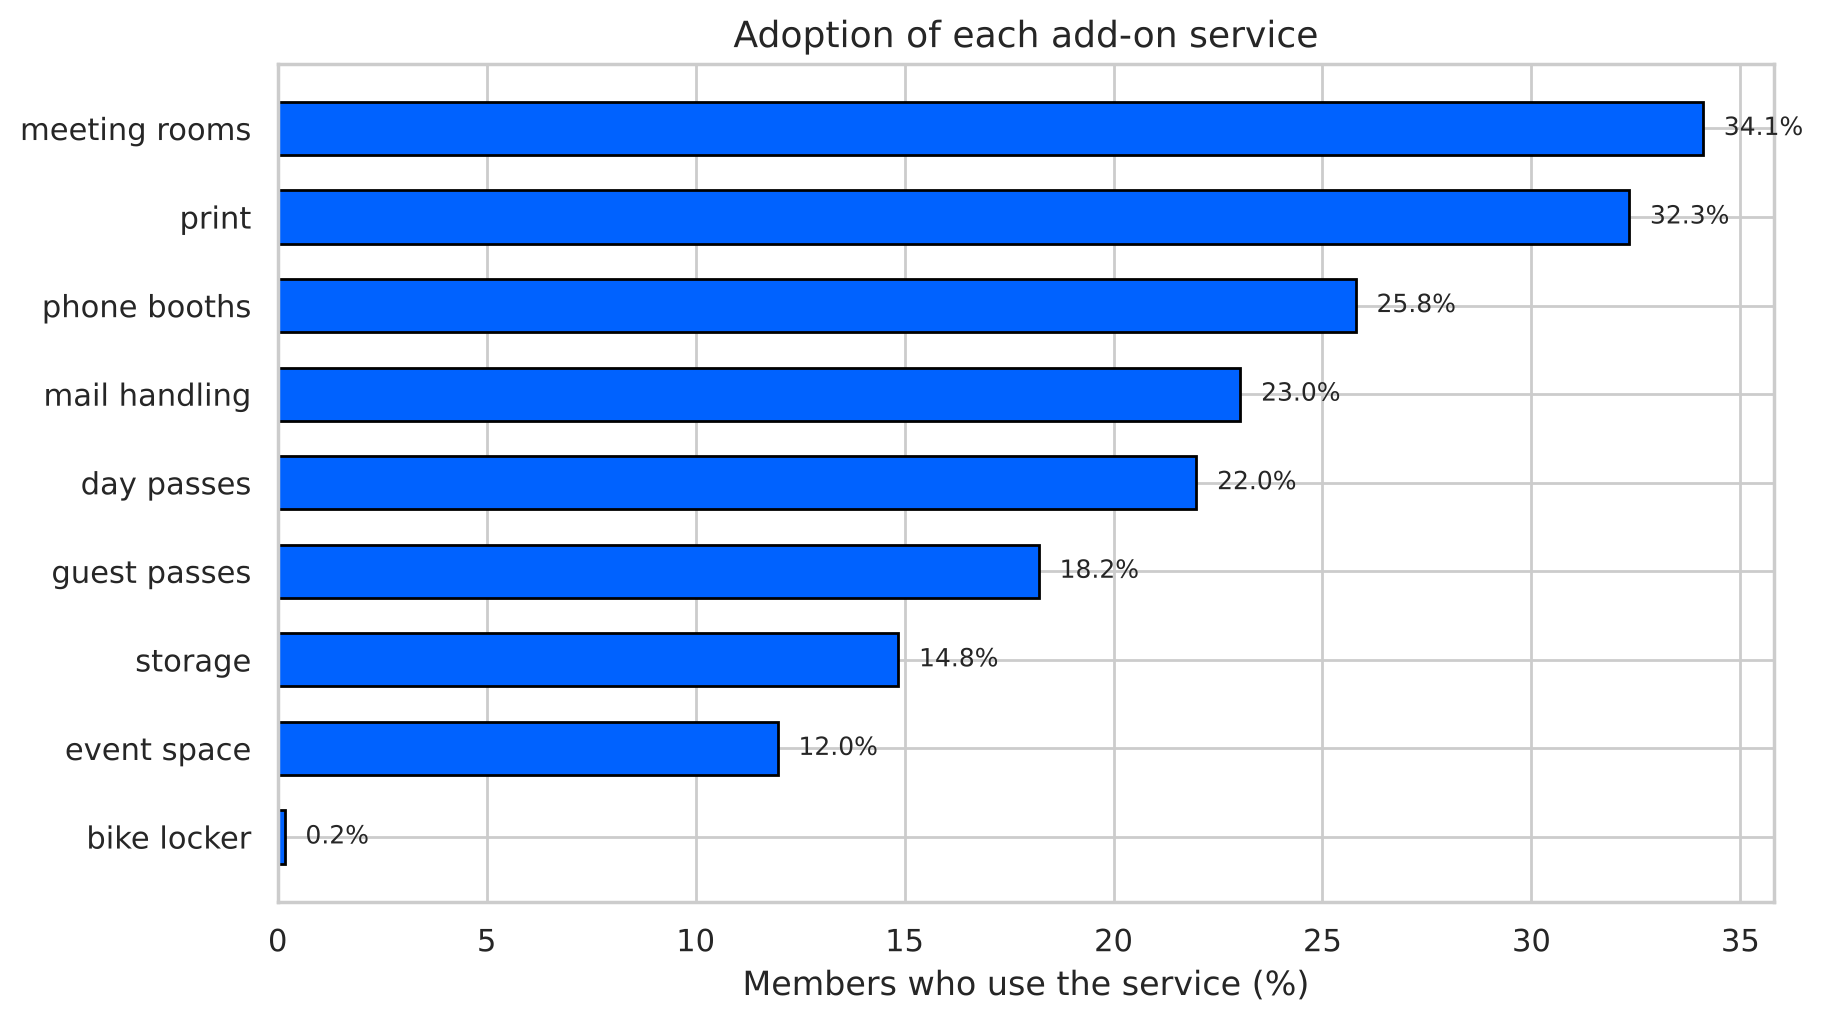

,% of members
Add-ons used,
0,20.0
1,30.0
2,20.9
3,13.9
4,9.1
5,4.5
6,1.4
7,0.2
8,0.0


In [35]:
plot_addon_adoption(eda_before)

Flex and hot desk together are about two thirds of the members, and the premium plans are small (private office is around 4%). Only about a quarter of the memberships are still active and half of the members never renewed, so keeping members seems to be ACDC's biggest problem.

Most people are based in Portugal and IT is the largest industry. Gender is fairly balanced. Around 28% of the accounts belong to a team.

Add-ons are used quite selectively. Meeting rooms and printing are the most common (roughly a third of members each), the bike locker is basically never used, and one in five members uses no add-on at all.

### Plans: Value, Retention and Usage

Since the plan looked so important in the histograms, we compare the plans directly.

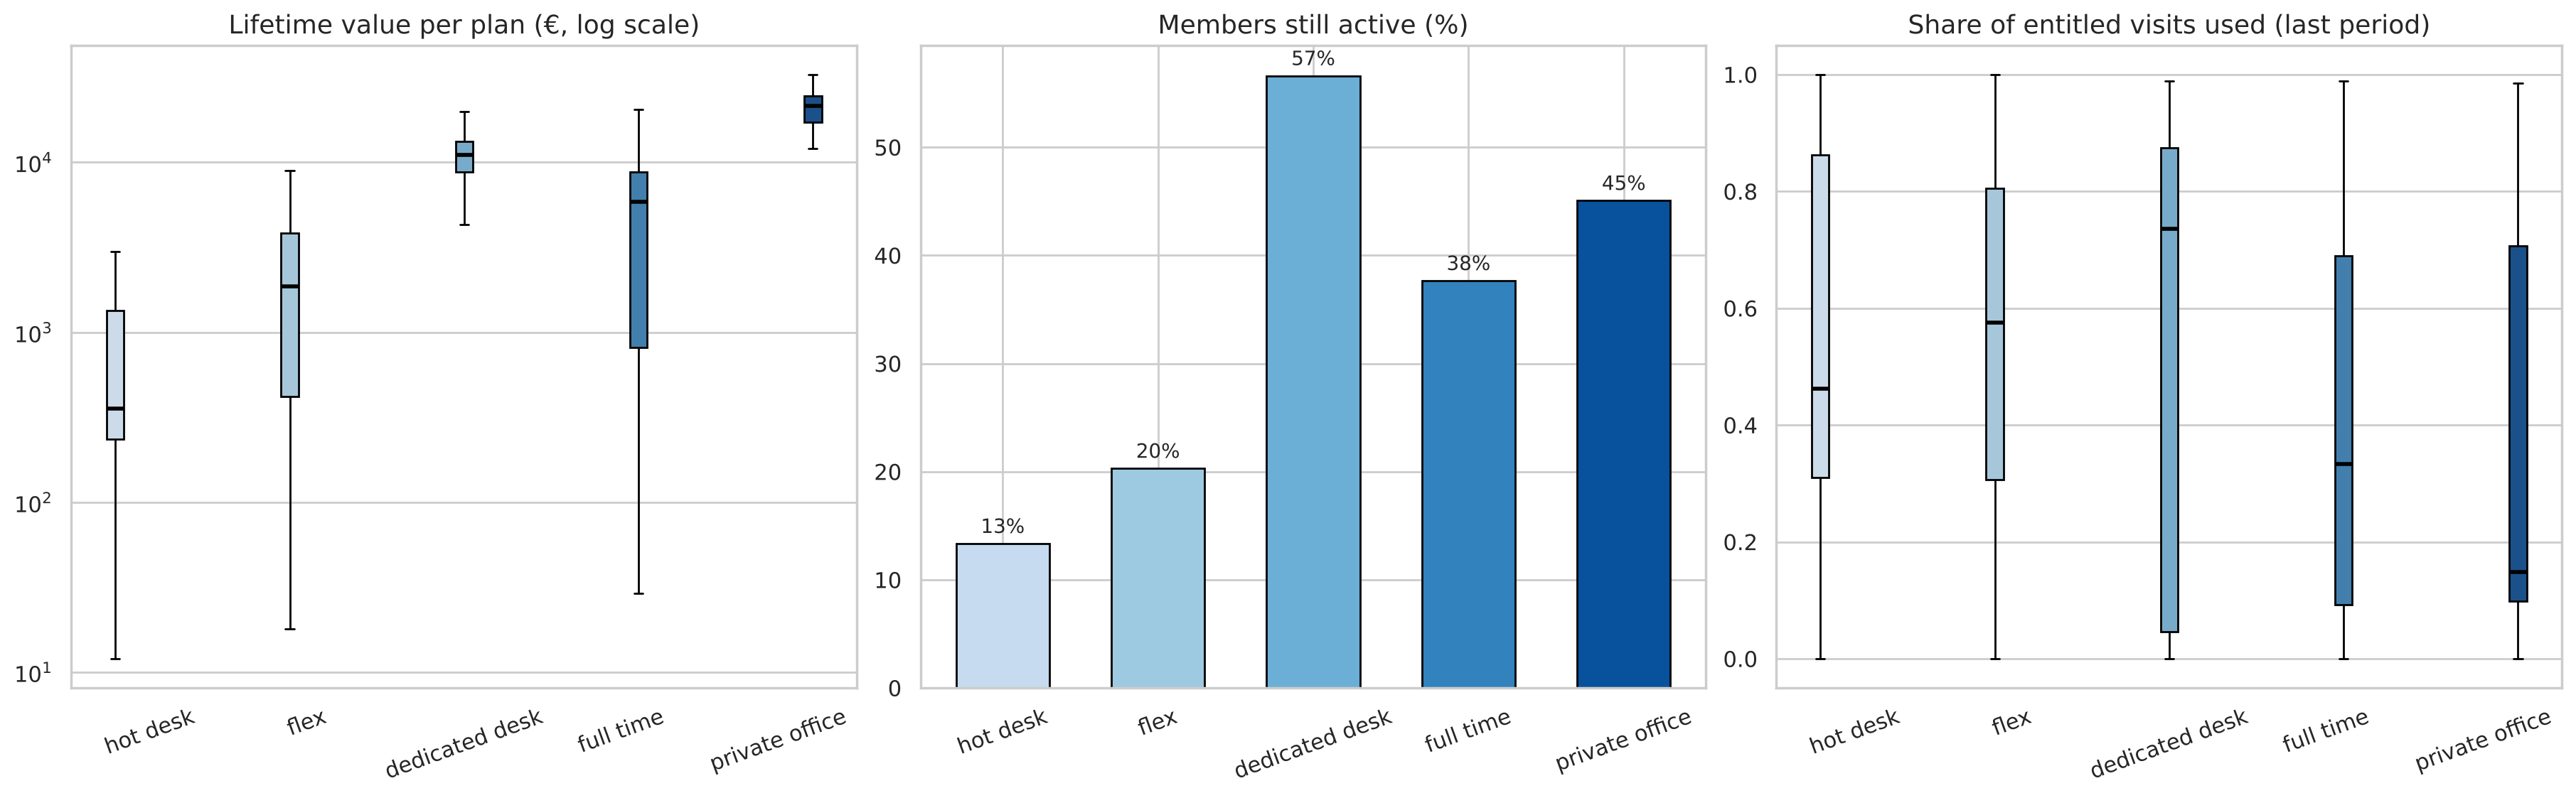

,members,median_lifetime_value,active_pct,median_utilisation,median_renewals
plan_tier,,,,,
hot desk,5153,355.73,13.33,0.46,0.0
flex,5394,1868.24,20.28,0.57,0.0
dedicated desk,1532,11036.10,56.59,0.74,2.0
full time,2444,5861.37,37.64,0.33,1.0
private office,657,21535.65,45.05,0.15,2.0


In [36]:
plot_plan_overview(eda_before)

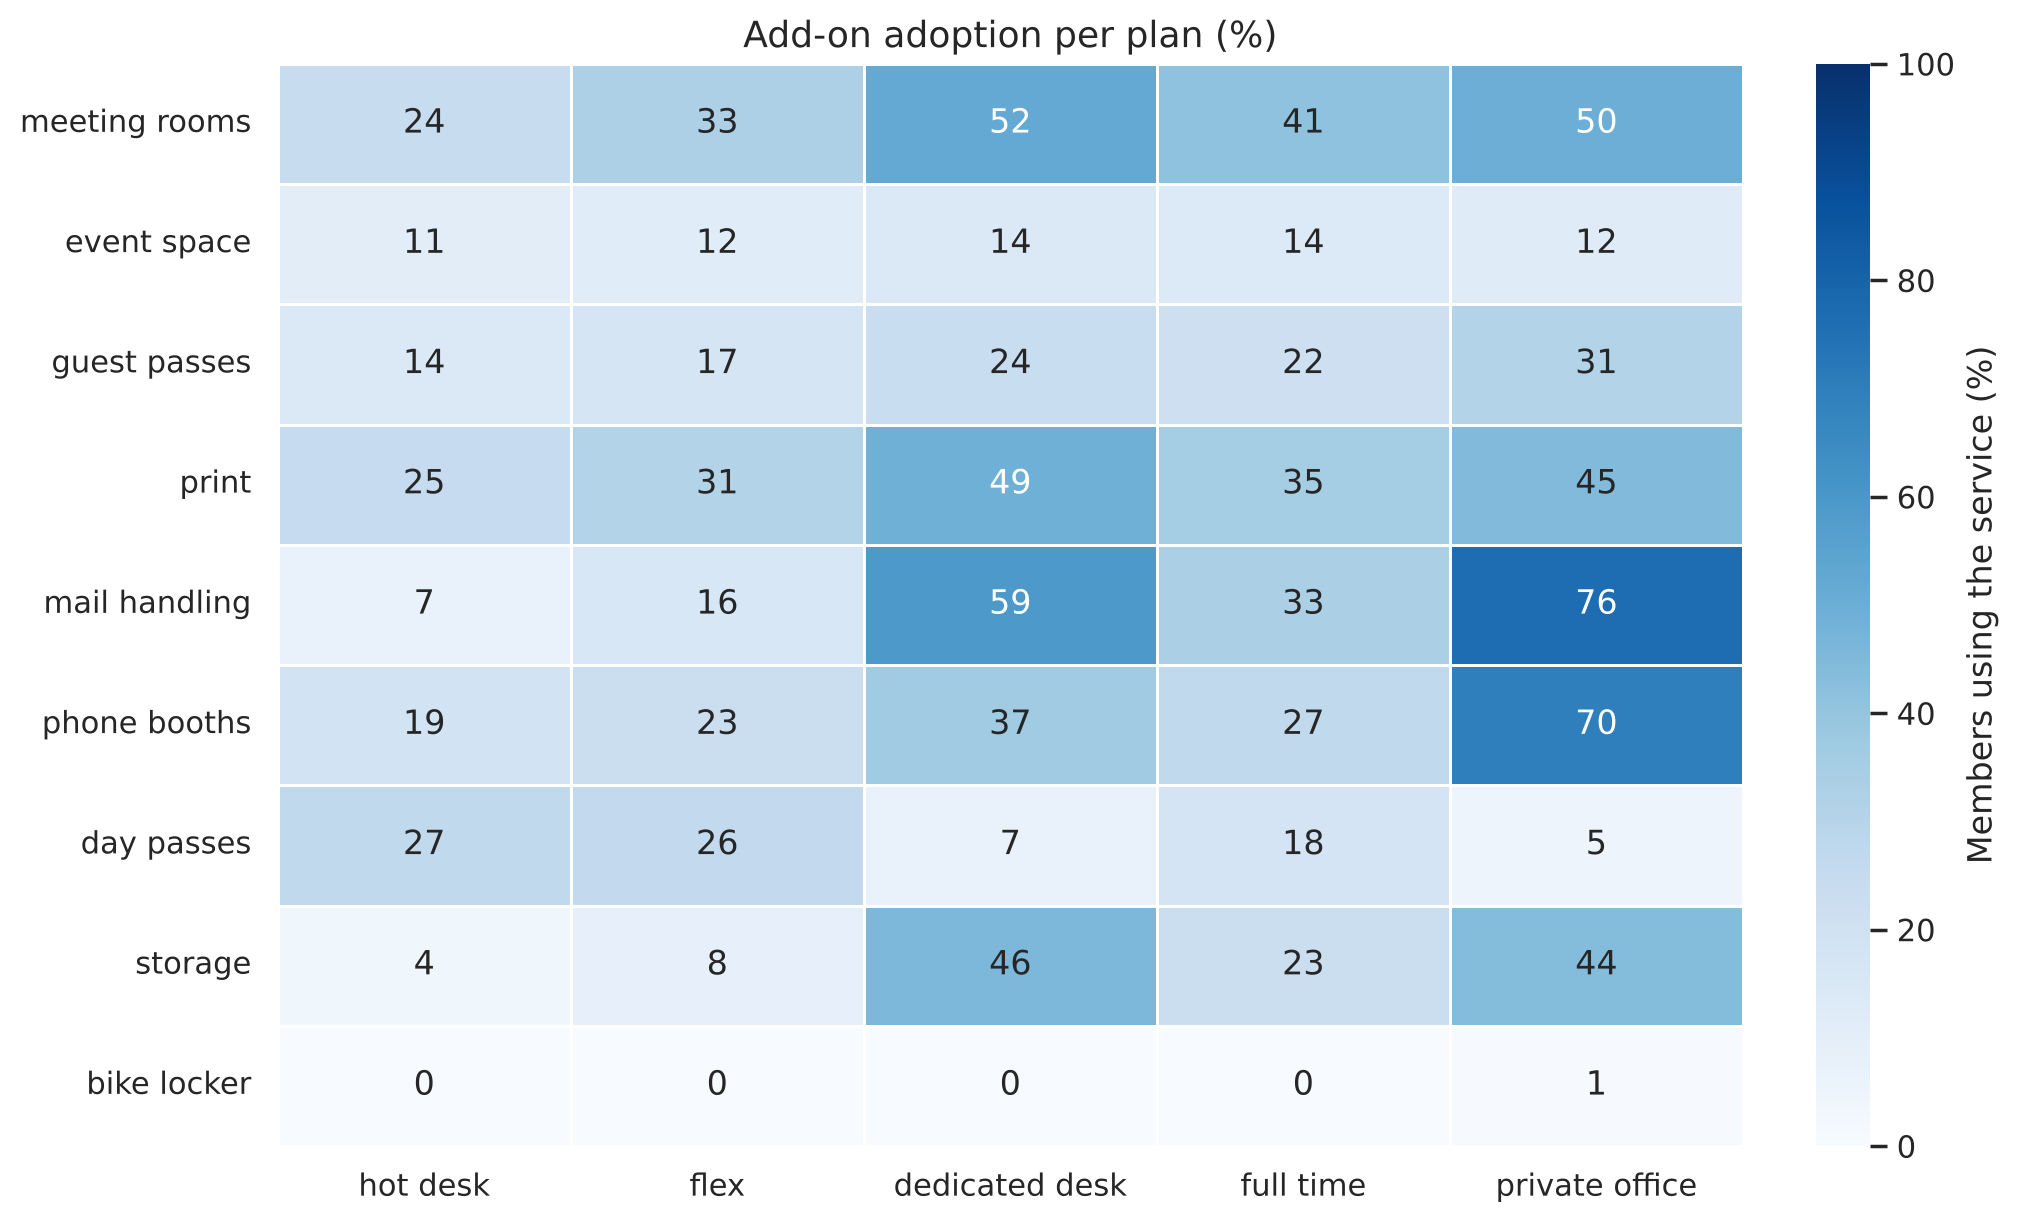

In [37]:
plot_addons_by_plan(eda_before)

Lifetime value grows a lot with the plan, from a median of a few hundred euros on hot desk to more than 20,000 € on private office. What surprised us is that dedicated desk members are worth almost twice as much as full time members, even though both plans give five days a week. They simply stay longer: more than half of the dedicated desk members are still active, against only 13% on hot desk.

Paying more does not mean coming more often, though. Dedicated desk members use most of their days, but private office members use only around 15% of theirs. Our guess is that many private offices are paid by companies and used now and then.

The add-ons also tell different stories per plan. Private office members use mail handling and phone booths a lot, which looks like a business address. Dedicated desk members use storage. Hot desk and flex members are the ones buying day passes.

### Usage Patterns

Here we look for differences between members on the same plan, since that is what clustering can add on top of the plan. Dividing actual visits by entitled visits puts every plan on the same 0 to 1 scale.

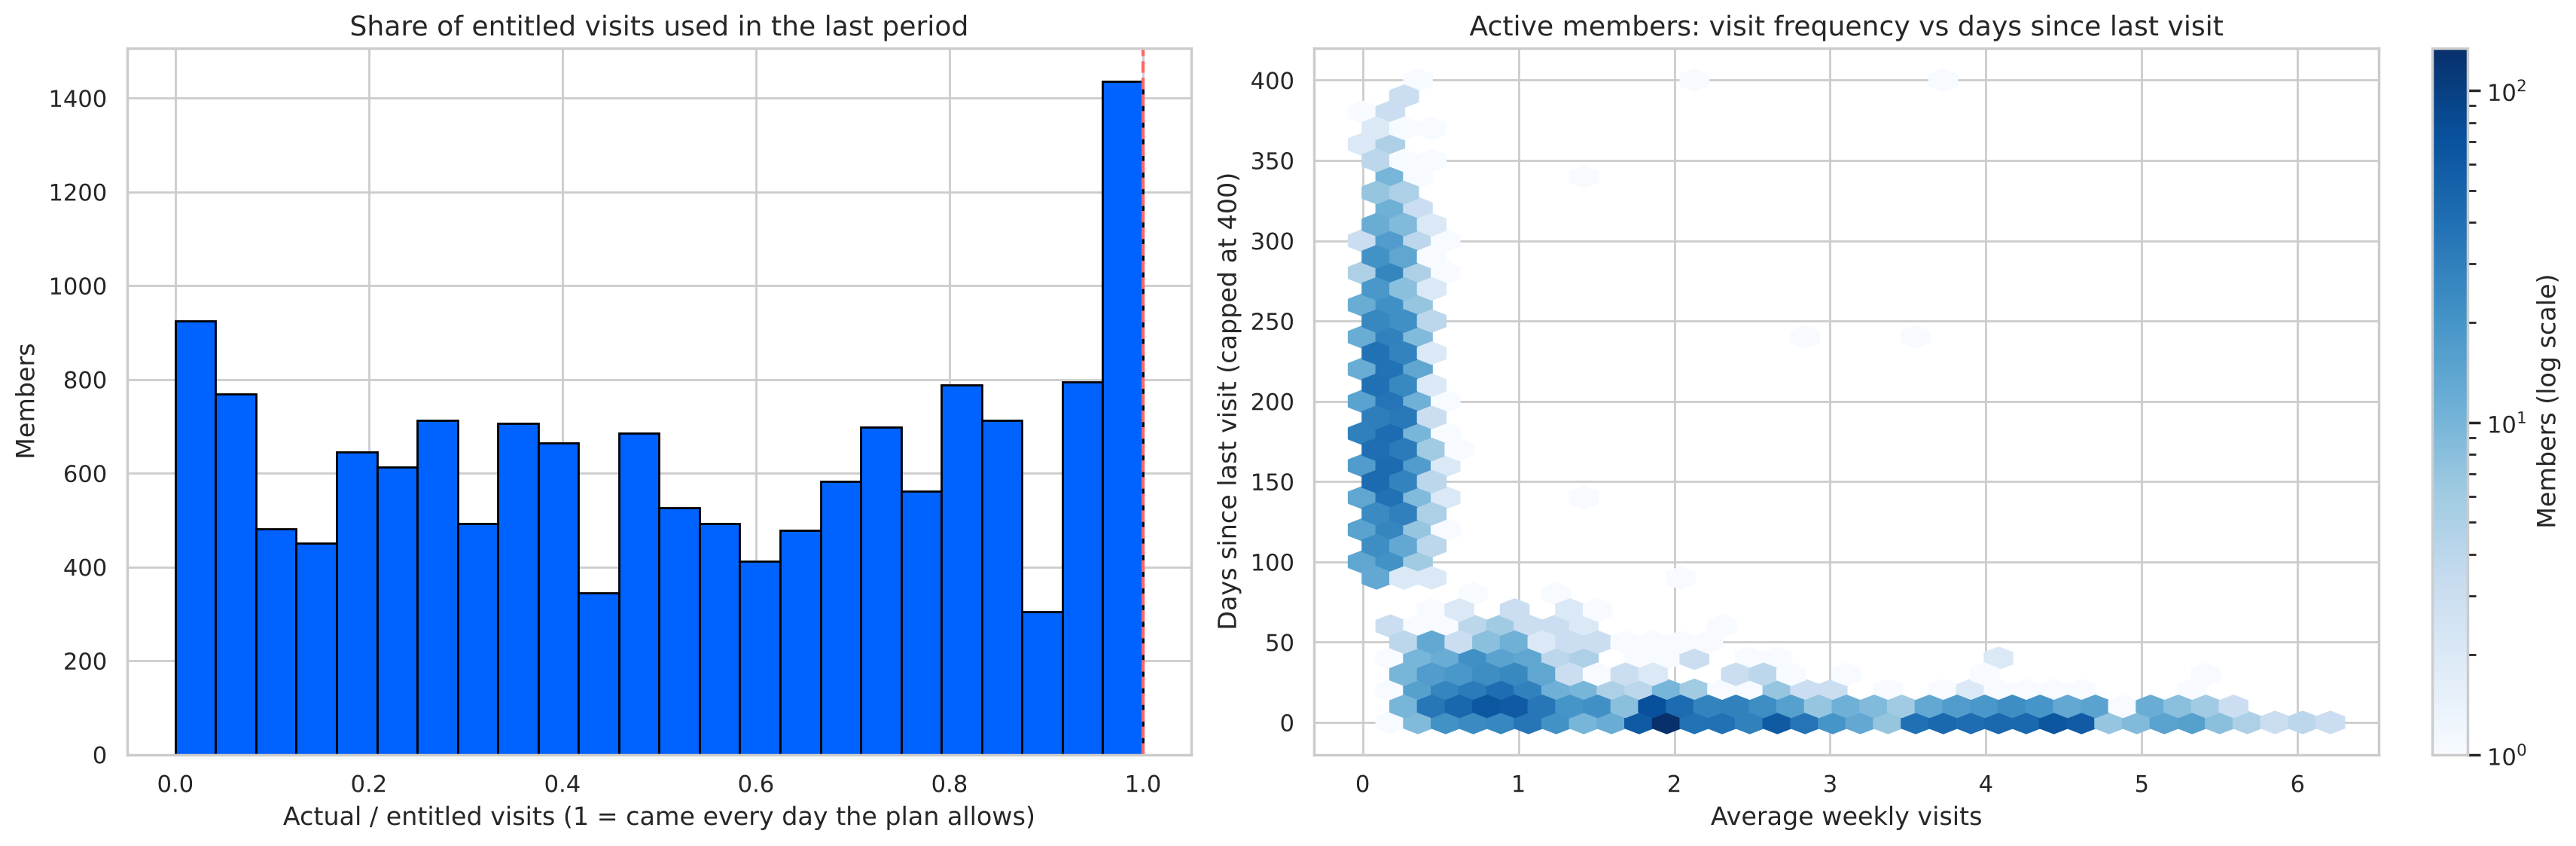

utilisation,below 20%,20-80%,above 80%
plan_tier,,,
hot desk,10.7,59.4,29.9
flex,15.0,58.8,26.1
dedicated desk,34.7,25.3,40.0
full time,34.4,51.7,13.9
private office,59.9,27.0,13.1


In [38]:
plot_usage_patterns(eda_before)

In [39]:
dormant_members(eda_before)

Active members: 3912  |  no visit for more than 90 days: 1287 (33%)


,% of dormant active members
plan_tier,
full time,39.4
dedicated desk,35.0
flex,25.6
hot desk,0.0
private office,0.0


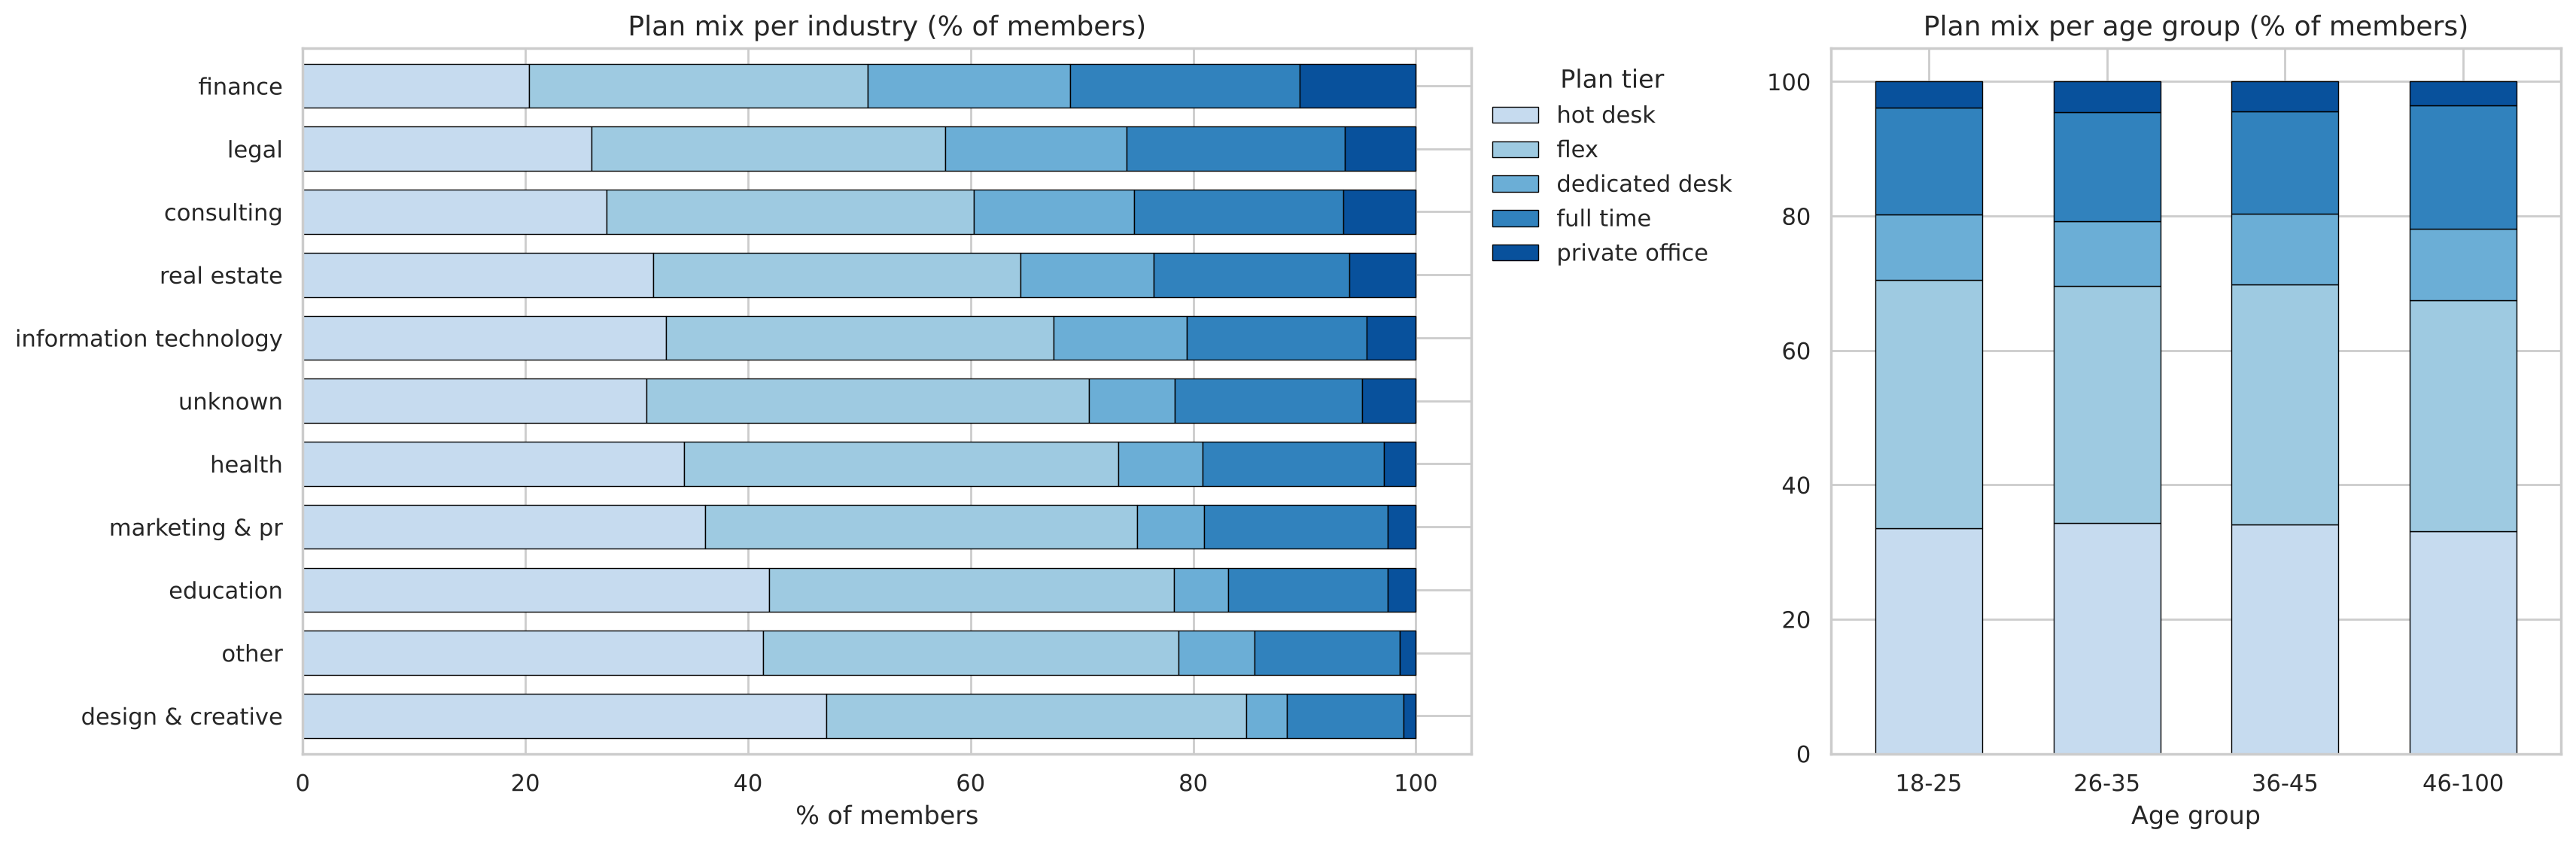

is_team_account,False,True
plan_tier,,
hot desk,71.9,28.1
flex,71.2,28.8
dedicated desk,72.4,27.6
full time,73.1,26.9
private office,68.5,31.5


In [40]:
plot_profile_vs_plan(eda_before)

Utilisation is not a nice bell curve. There is a big group at 1, members who come every day they are allowed to, and another big group close to 0. These two groups exist in every plan. On dedicated desk, for example, about a third of members use less than 20% of their days while 40% use more than 80%.

The hexbin shows something similar for active members: most come regularly and were in recently, but there is a separate group with less than one visit every two weeks that has not been in for months. About one in three active members has not visited in over 90 days, mostly on full time, dedicated desk and flex. They are still paying, but they look likely to leave.

Age and team accounts barely change the plan mix. Industry matters a bit more, with finance, legal and consulting choosing more premium plans and design & creative relying more on hot desk and flex. So these variables seem more useful to describe the clusters later than to build them.

### What This Means for the Segmentation

Putting it together, how much a member pays and how much they use the space are clearly two different things, which fits well with doing a value-based and a behavioural segmentation separately.

At this point we would expect around four or five groups: short-term occasional users on the cheaper plans, regulars who use most of what they pay for, loyal dedicated desk members with a high value, premium accounts that work more like a business address, and members who are still active but have stopped coming.

The biggest risks for the clustering are the very skewed service variables, the errors and placeholders listed above, and variables that repeat the same information (for example `actual_visits_last_period` and `avg_weekly_visits`). The first two are dealt with in the cleaning below.

## Cleanup

In [41]:
mean_age = dataset.loc[(dataset["age"] >= 18) & (dataset["age"] <= 100), "age"].mean()

dataset.loc[(dataset["age"] < 18) | (dataset["age"] > 100), "age"] = mean_age

In [42]:
dataset["is_active"] = dataset["membership_end"] == "1970-01-01"
dataset.loc[dataset["is_active"], "membership_end"] = pd.NaT

In [43]:
invalid_period = dataset["membership_end"] < dataset["membership_start"]
print("Memberships that end before they start:", invalid_period.sum())
dataset[invalid_period].head()

Memberships that end before they start: 149


,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
member_id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
CW000161,NaN,female,marketing & pr,portugal,False,0,flex,3,2021-10-25,2021-10-17,2023-02-12,5,161,2.36,26.09,20,24.5,0.0,0.0,True,False,False,True,False,False,False,False,False,1,3255.60,False
CW000284,42.0,other,design & creative,france,True,4,hot desk,2,2021-03-19,2021-03-12,2022-08-11,6,83,1.13,17.39,10,0.0,129.5,135.0,False,True,True,False,False,True,False,False,False,0,10056.58,False
CW000315,39.0,female,design & creative,portugal,False,0,hot desk,2,2021-08-17,2021-06-29,2021-08-17,999,7,0.99,14.29,7,0.0,0.0,0.0,False,False,False,False,True,True,True,False,False,0,0.00,False
CW000480,43.0,female,design & creative,spain,False,0,flex,3,2021-10-09,2021-09-15,2022-05-13,-240,85,2.70,26.09,20,0.0,0.0,0.0,False,False,False,False,False,False,True,False,False,0,1513.76,False
CW000498,NaN,female,design & creative,portugal,True,1,full time,5,2022-05-10,2022-02-10,2023-11-15,-643,359,4.50,43.48,31,95.7,0.0,0.0,True,False,False,True,True,True,False,True,False,5,7349.95,False


In [44]:
dataset = dataset[~invalid_period].copy()

In [45]:
print("Rows left:", len(dataset))
print("Invalid periods left:", (dataset["membership_end"] < dataset["membership_start"]).sum())

Rows left: 15134
Invalid periods left: 0


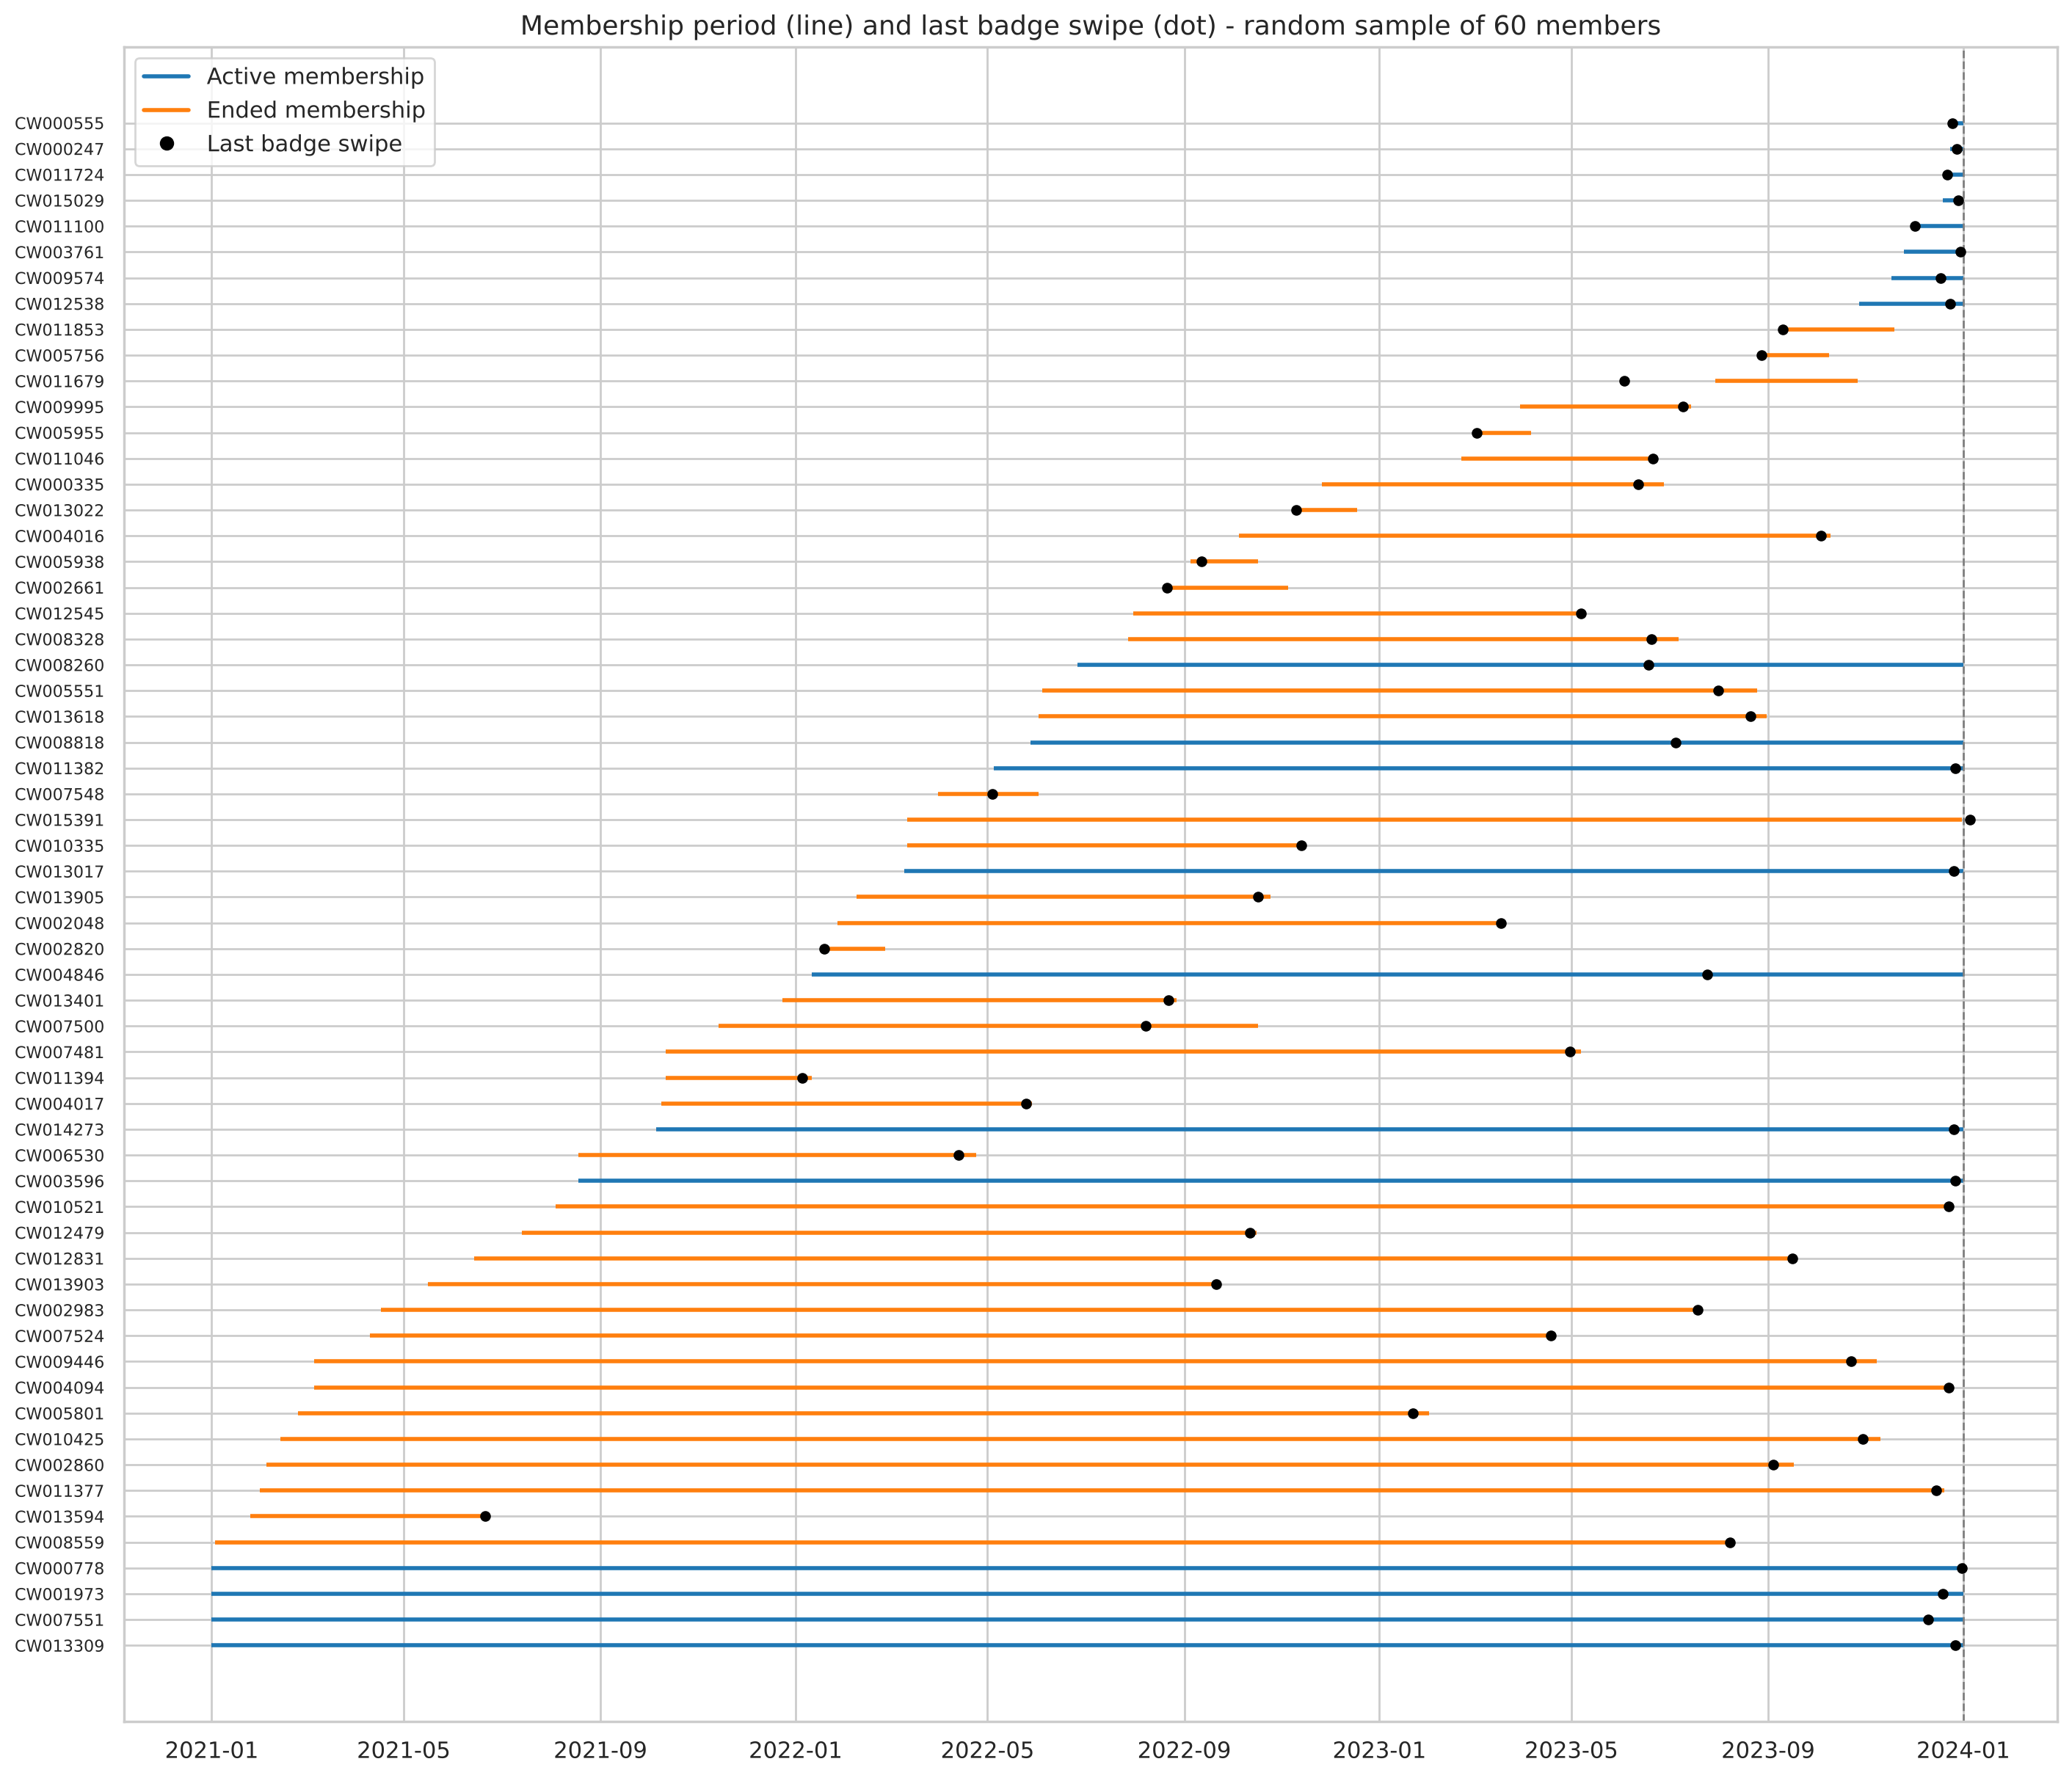

In [46]:
from matplotlib.lines import Line2D

EXTRACTION_DATE = pd.Timestamp("2024-01-01")

# Random sample of members (all 15,000 lines would overlap), ordered by start date
sample = dataset.sample(60, random_state=42).sort_values("membership_start")
membership_stop = sample["membership_end"].fillna(EXTRACTION_DATE)   # active members run until the extraction date
y = np.arange(len(sample))
colors = np.where(sample["is_active"], "tab:blue", "tab:orange")

fig, ax = plt.subplots(figsize=(14, 12), layout="constrained")

ax.hlines(y, sample["membership_start"], membership_stop, colors=colors, linewidth=2)   # membership period
ax.scatter(sample["last_badge_swipe"], y, color="black", s=18, zorder=3)                # last badge swipe
ax.axvline(EXTRACTION_DATE, color="gray", linestyle="--", linewidth=1)                  # extraction date

ax.set_yticks(y, sample.index, fontsize=8)
ax.set_title("Membership period (line) and last badge swipe (dot) - random sample of 60 members", fontsize=13)

legend = [
    Line2D([0], [0], color="tab:blue", linewidth=2, label="Active membership"),
    Line2D([0], [0], color="tab:orange", linewidth=2, label="Ended membership"),
    Line2D([0], [0], marker="o", color="black", linewidth=0, label="Last badge swipe"),
]
ax.legend(handles=legend, loc="upper left")

plt.show()


In [47]:
swipe_after_end = dataset["last_badge_swipe"] > dataset["membership_end"]
print(f"Members who swiped in after their membership ended: {swipe_after_end.sum()} ({swipe_after_end.mean():.1%})")
dataset = dataset[~swipe_after_end].copy()

Members who swiped in after their membership ended: 61 (0.4%)


instead of deleting use last day of membership for example

In [48]:
# Badge swipes after the extraction date are impossible
future_swipe = dataset["last_badge_swipe"] > EXTRACTION_DATE
print(f"Badge swipes after the extraction date: {future_swipe.sum()} ({future_swipe.mean():.1%})")

# remove them
dataset = dataset[~future_swipe].copy()

Badge swipes after the extraction date: 27 (0.2%)


there is also members whose last visit is before their membership started

In [49]:
dataset["days_since_last_visit"] = dataset["days_since_last_visit"].replace(999, np.nan)
dataset["n_colleagues_on_account"] = dataset["n_colleagues_on_account"].replace(-1, np.nan)
dataset["plan_days_per_week"] = dataset["plan_days_per_week"].apply(lambda x: x if x in [2, 3, 5, 7] else np.nan)
dataset["industry"] =dataset["industry"].replace("unknown", np.nan)
dataset["age"] = dataset["age"].round().astype("Int64")


In [50]:
# avg_weekly_visits above 7 (more than one visit per day) is impossible
dataset.loc[dataset["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan

In [51]:
# Negative service amounts are sign typos: every one of these members is flagged as a user of the service
for column in ["meeting_room_hours", "event_space_hours", "guest_passes_issued"]:
    negative = dataset[column] < 0
    print(f"{column}: {negative.sum()} negative values made positive")
    dataset.loc[negative, column] = dataset.loc[negative, column].abs()

meeting_room_hours: 16 negative values made positive
event_space_hours: 8 negative values made positive
guest_passes_issued: 7 negative values made positive


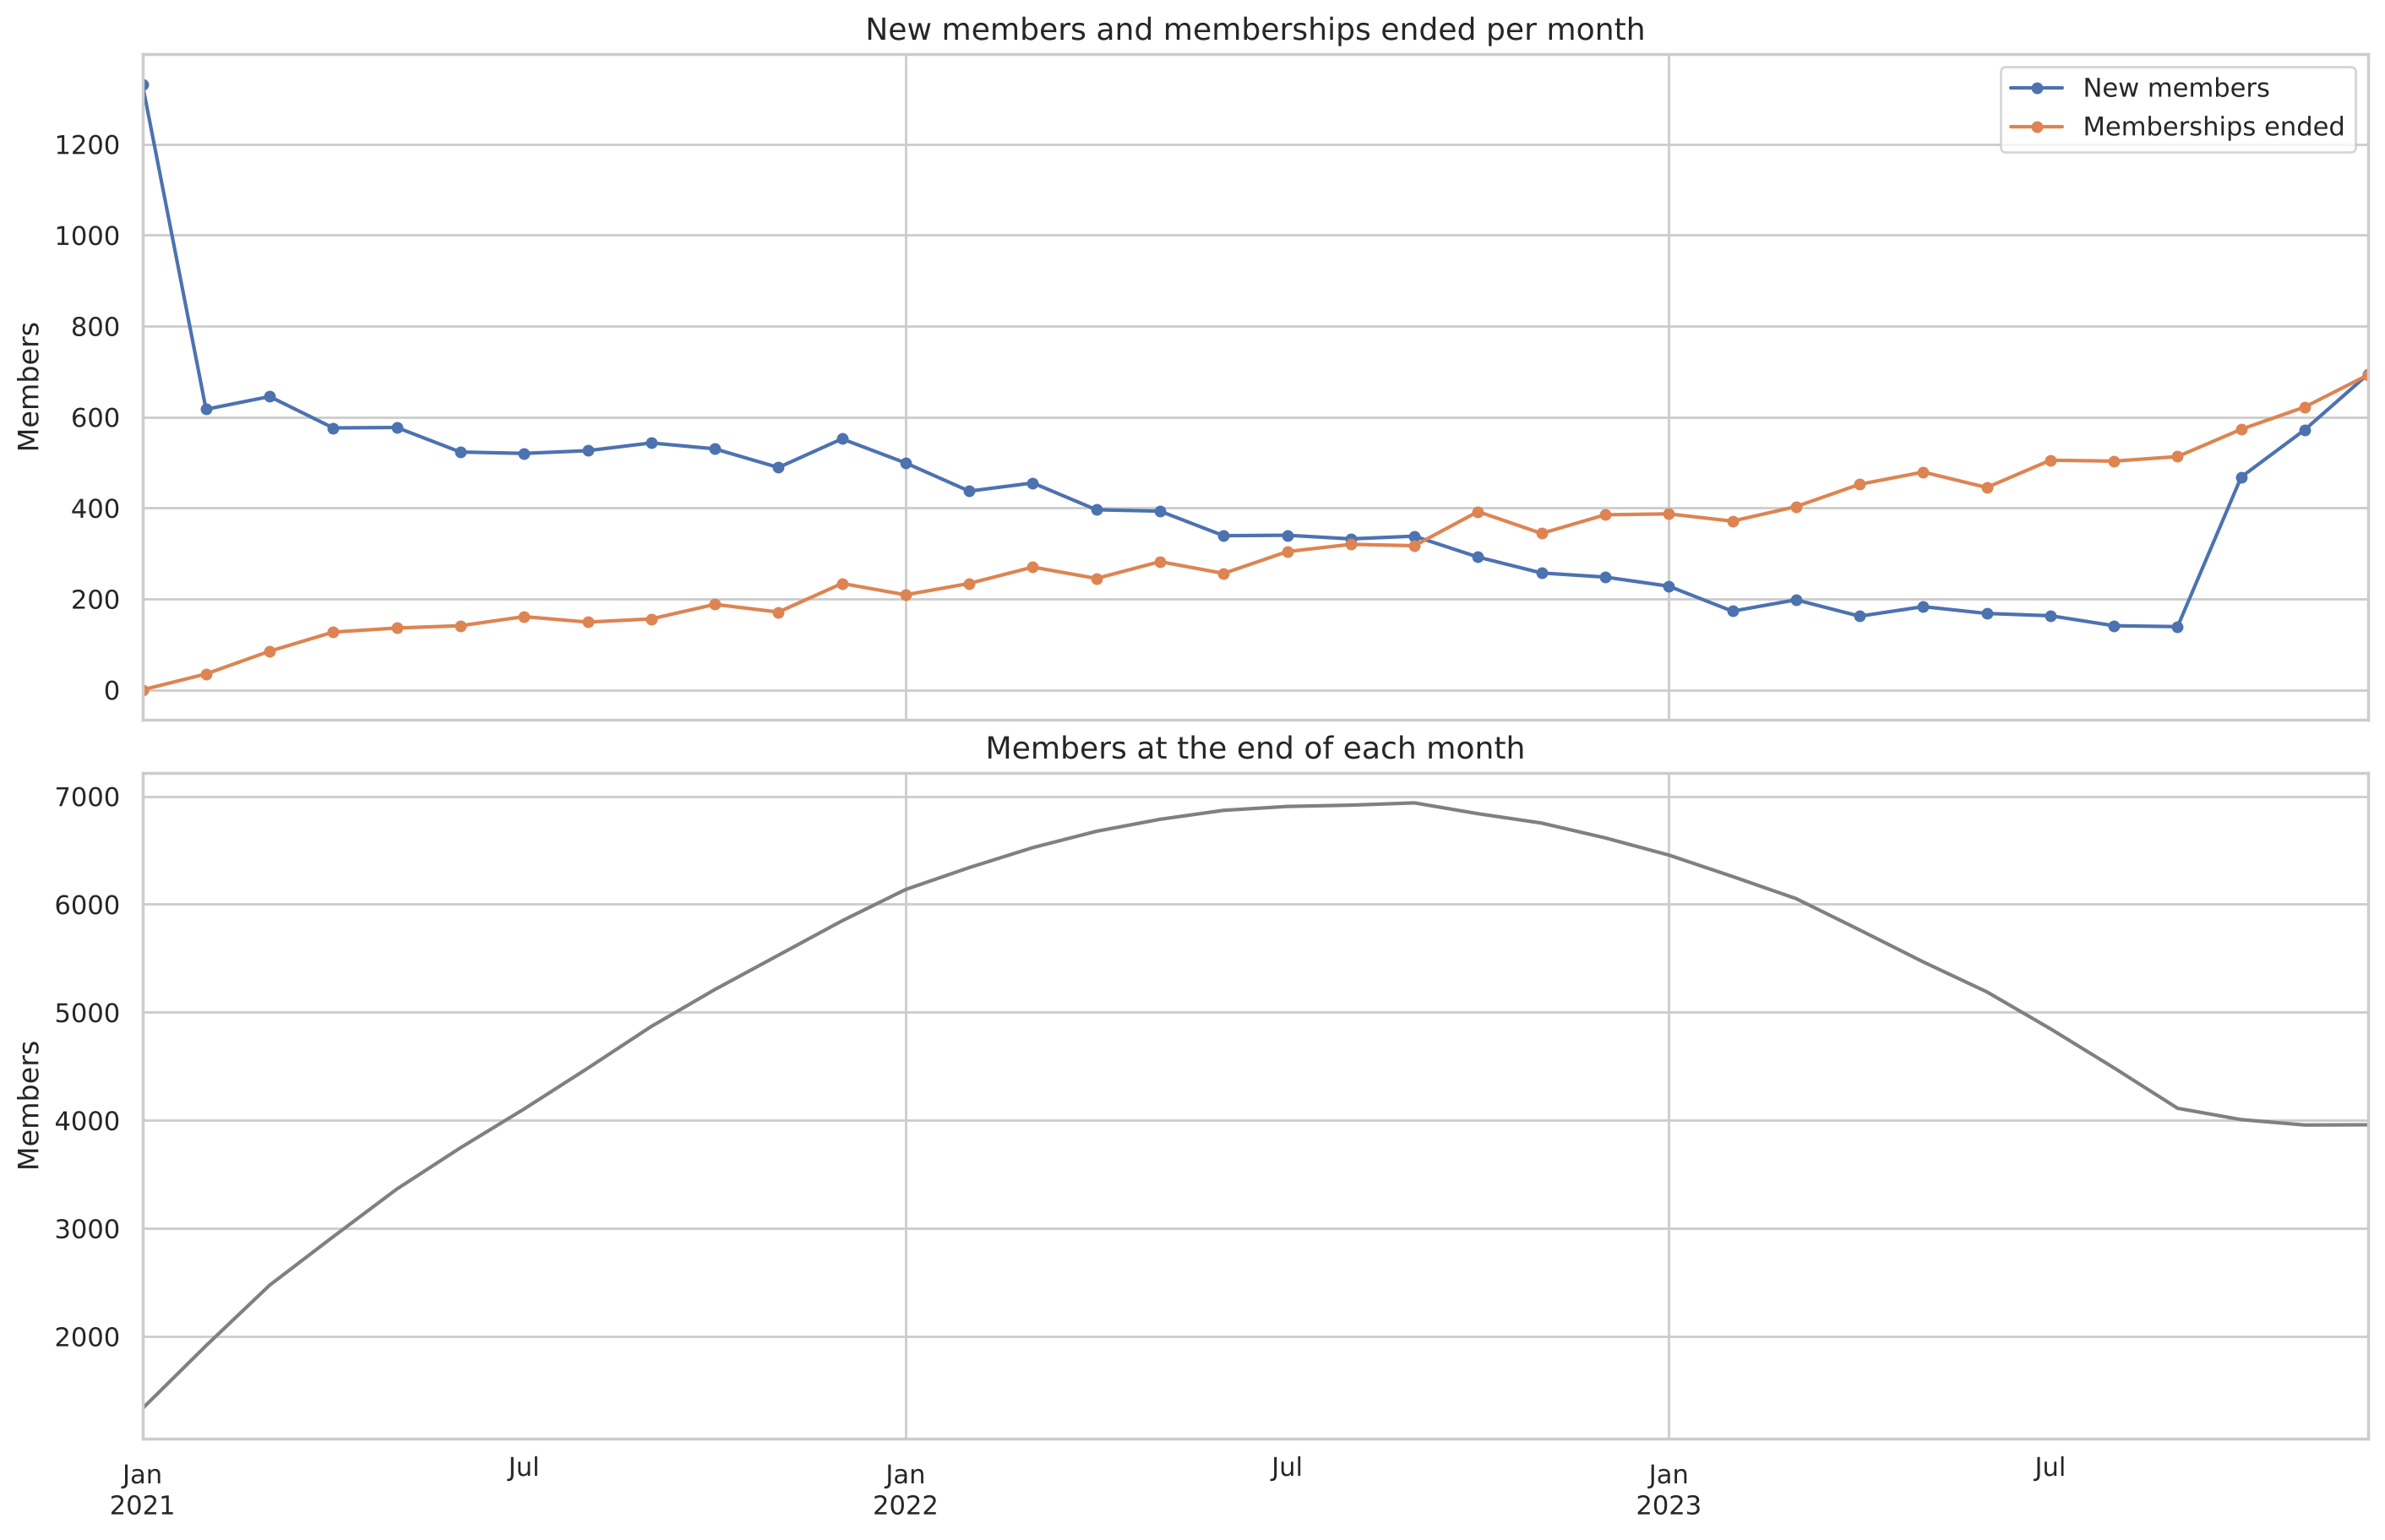

In [52]:
# New members and ended memberships per month, within the 3-year data period
starts = dataset["membership_start"].dt.to_period("M").value_counts()
ends = dataset["membership_end"].dt.to_period("M").value_counts()

monthly = pd.DataFrame({"New members": starts, "Memberships ended": ends}).fillna(0).sort_index()
monthly = monthly.loc["2021-01":"2023-12"]
monthly.index = monthly.index.to_timestamp()

# Members at the end of each month: everyone who joined minus everyone who left so far
members_per_month = (monthly["New members"] - monthly["Memberships ended"]).cumsum()

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, layout="constrained")

monthly.plot(ax=axes[0], marker="o", markersize=4)
axes[0].set_title("New members and memberships ended per month", fontsize=13)
axes[0].set_ylabel("Members")
axes[0].set_xlabel("")

members_per_month.plot(ax=axes[1], color="gray")
axes[1].set_title("Members at the end of each month", fontsize=13)
axes[1].set_ylabel("Members")
axes[1].set_xlabel("")

plt.show()


In [53]:
service_columns = {
    "meeting_room_hours": "uses_meeting_rooms",
    "event_space_hours": "uses_event_space",
    "guest_passes_issued": "uses_guest_passes",
}

# A member used a service if the recorded amount is above 0 (the amounts are more specific than the flags)
for amount, flag in service_columns.items():
    recorded = dataset[amount].notna()
    inconsistent = recorded & (dataset[flag] != (dataset[amount] > 0))
    print(f"{flag}: {inconsistent.sum()} flags corrected")
    dataset.loc[recorded, flag] = dataset.loc[recorded, amount] > 0

uses_meeting_rooms: 61 flags corrected
uses_event_space: 71 flags corrected
uses_guest_passes: 121 flags corrected


some flags were set to false but there were values like `uses meeting room` = false but `meeting room hours` > 0

In [54]:
dataset["tenure_days"] = (dataset["membership_end"].fillna(EXTRACTION_DATE) - dataset["membership_start"]).dt.days

In [55]:
dataset.loc[dataset["lifetime_value"] == 0, "lifetime_value"] = np.nan

## Visualisations After Cleaning

With the cleaning done, we run the same charts again to check that the problems are gone and that what we saw before still holds.

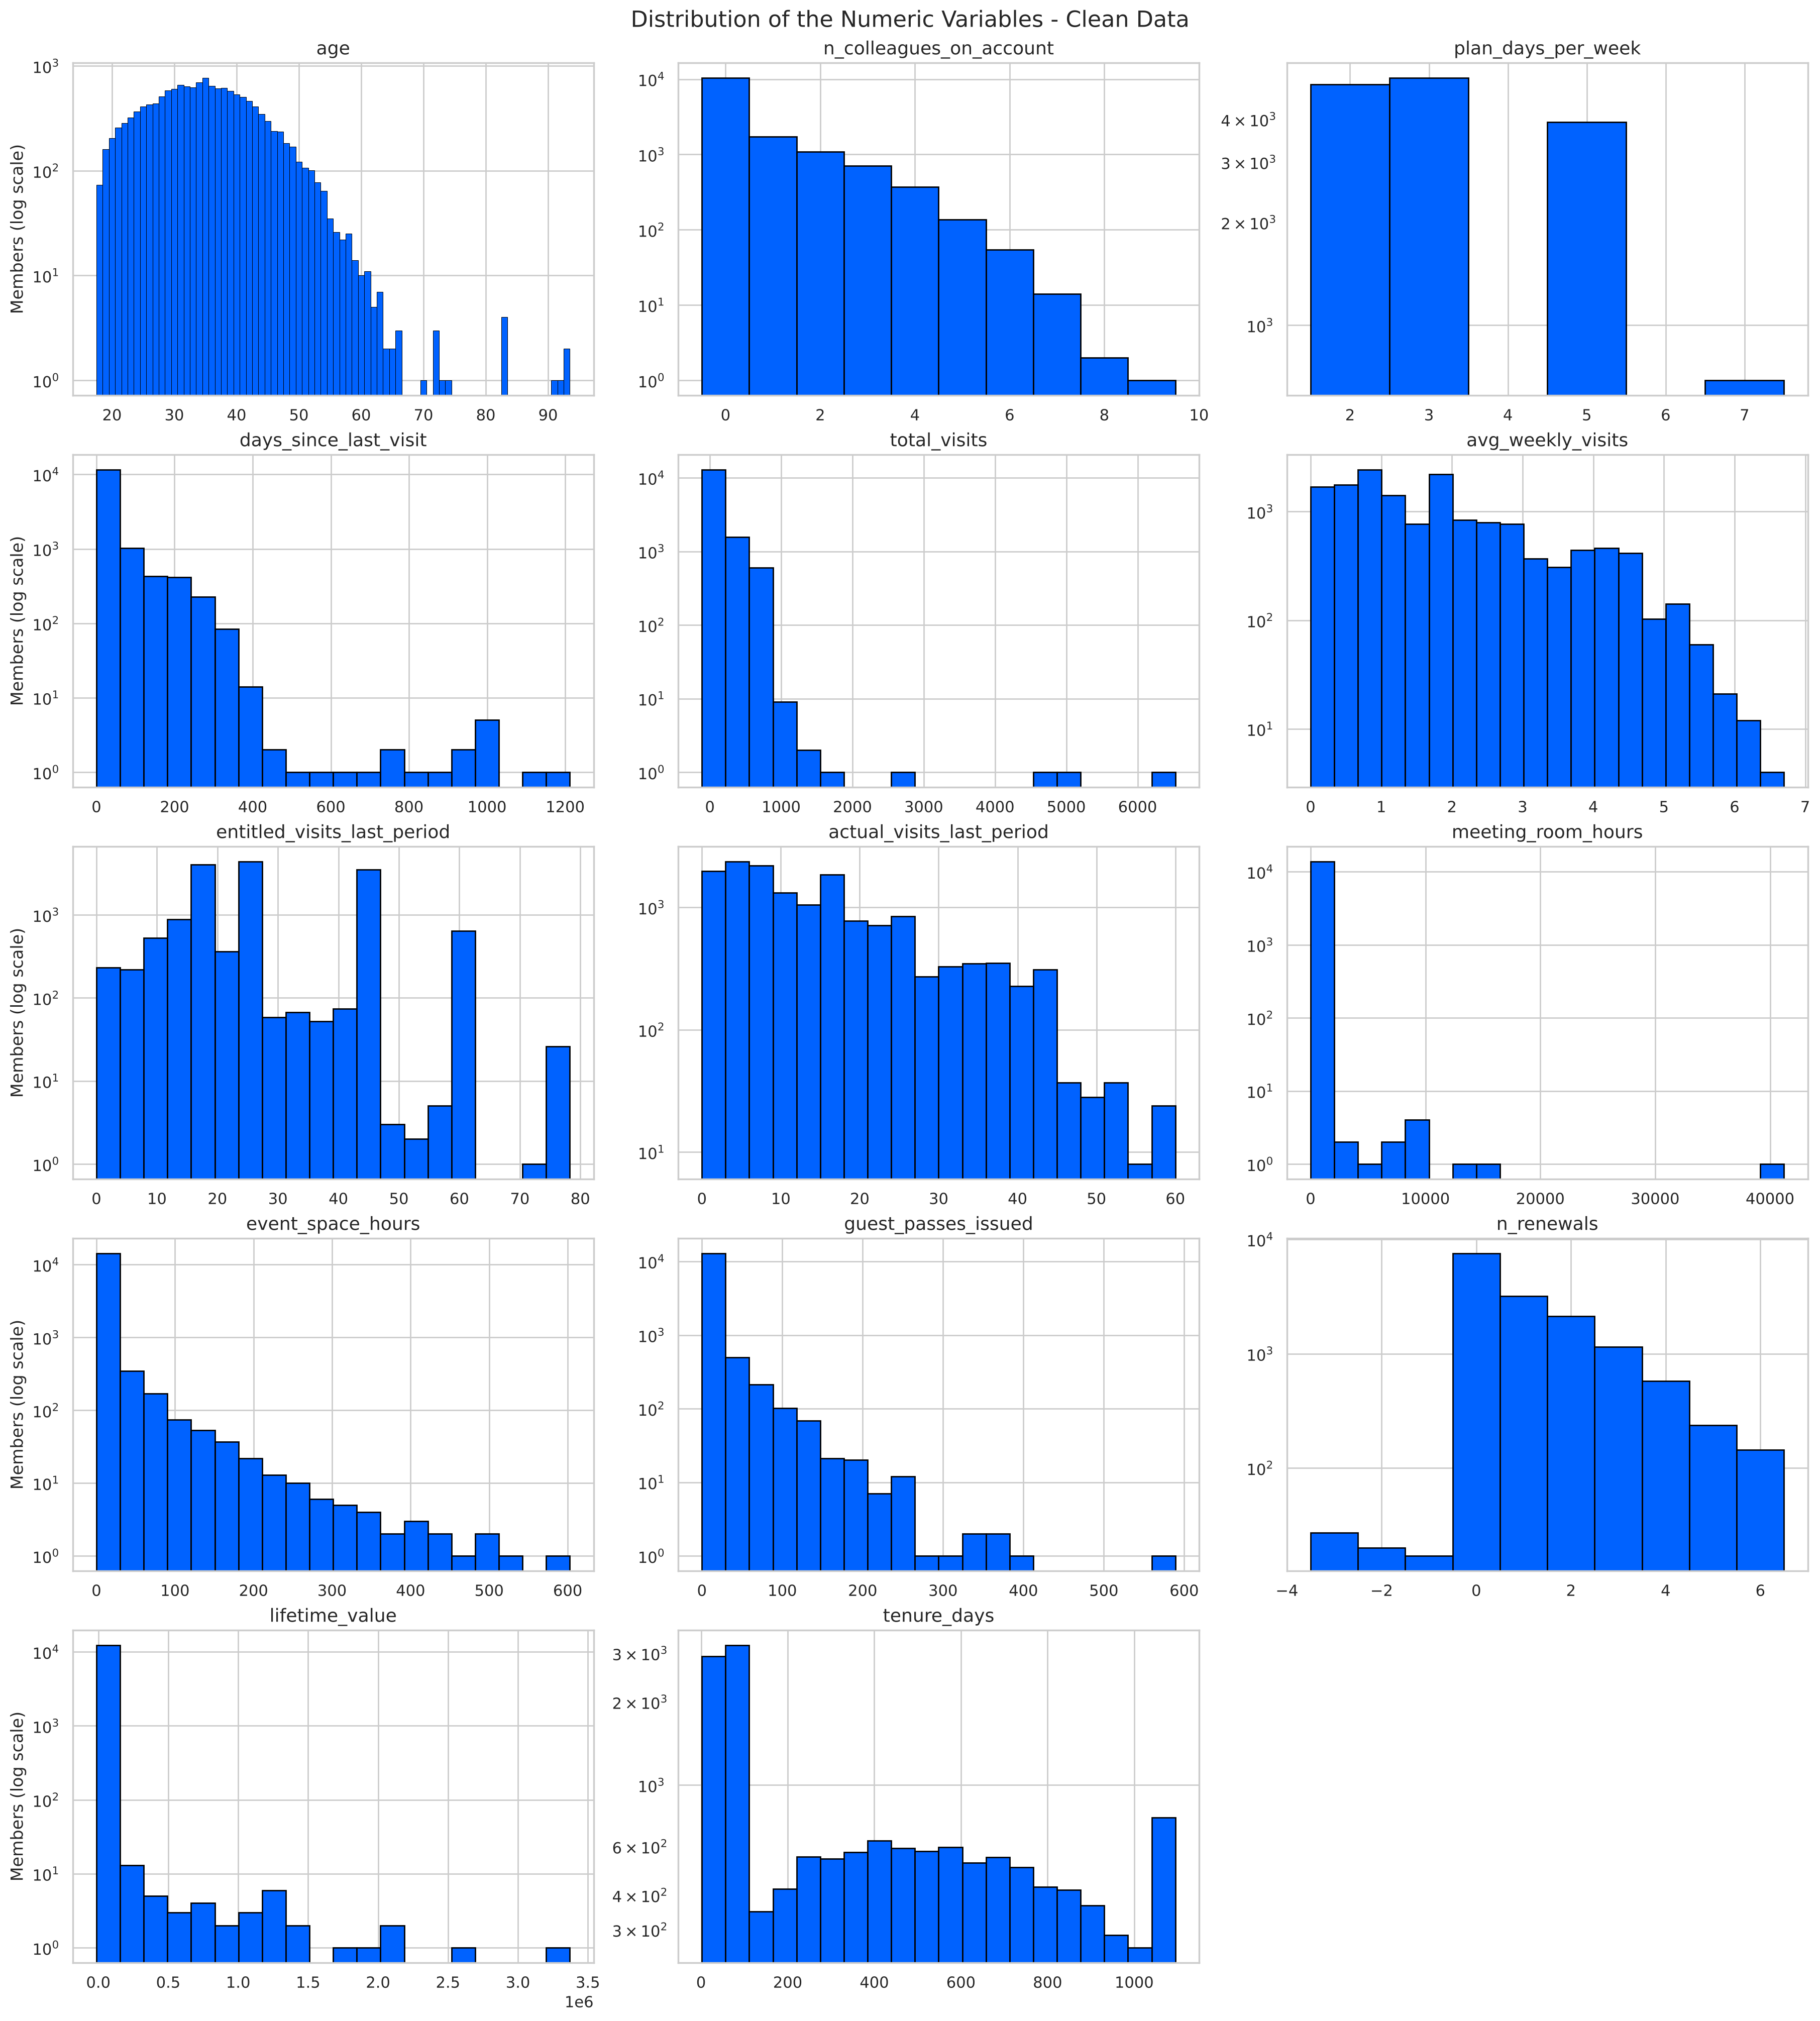

In [56]:
plot_histograms(dataset, numeric_features + ["lifetime_value", "tenure_days"], "Distribution of the Numeric Variables - Clean Data",
                discrete_features=["age", "n_colleagues_on_account", "plan_days_per_week", "n_renewals"])

Several problems are gone: ages are now between 18 and 93, `n_colleagues_on_account` no longer has the -1, `plan_days_per_week` only has the four real plans, and `days_since_last_visit` lost the spike at 999 (it is now on a normal scale, so the remaining tail is easier to see).

The plots also show what the cleaning still has to handle. `total_visits` still goes up to about 6,500 and `meeting_room_hours` up to about 41,000, `n_renewals` still has negative values, and `lifetime_value` still has a few members in the millions of euros, which squashes the whole histogram to the left. These need to be fixed (or treated as outliers) before the clustering.

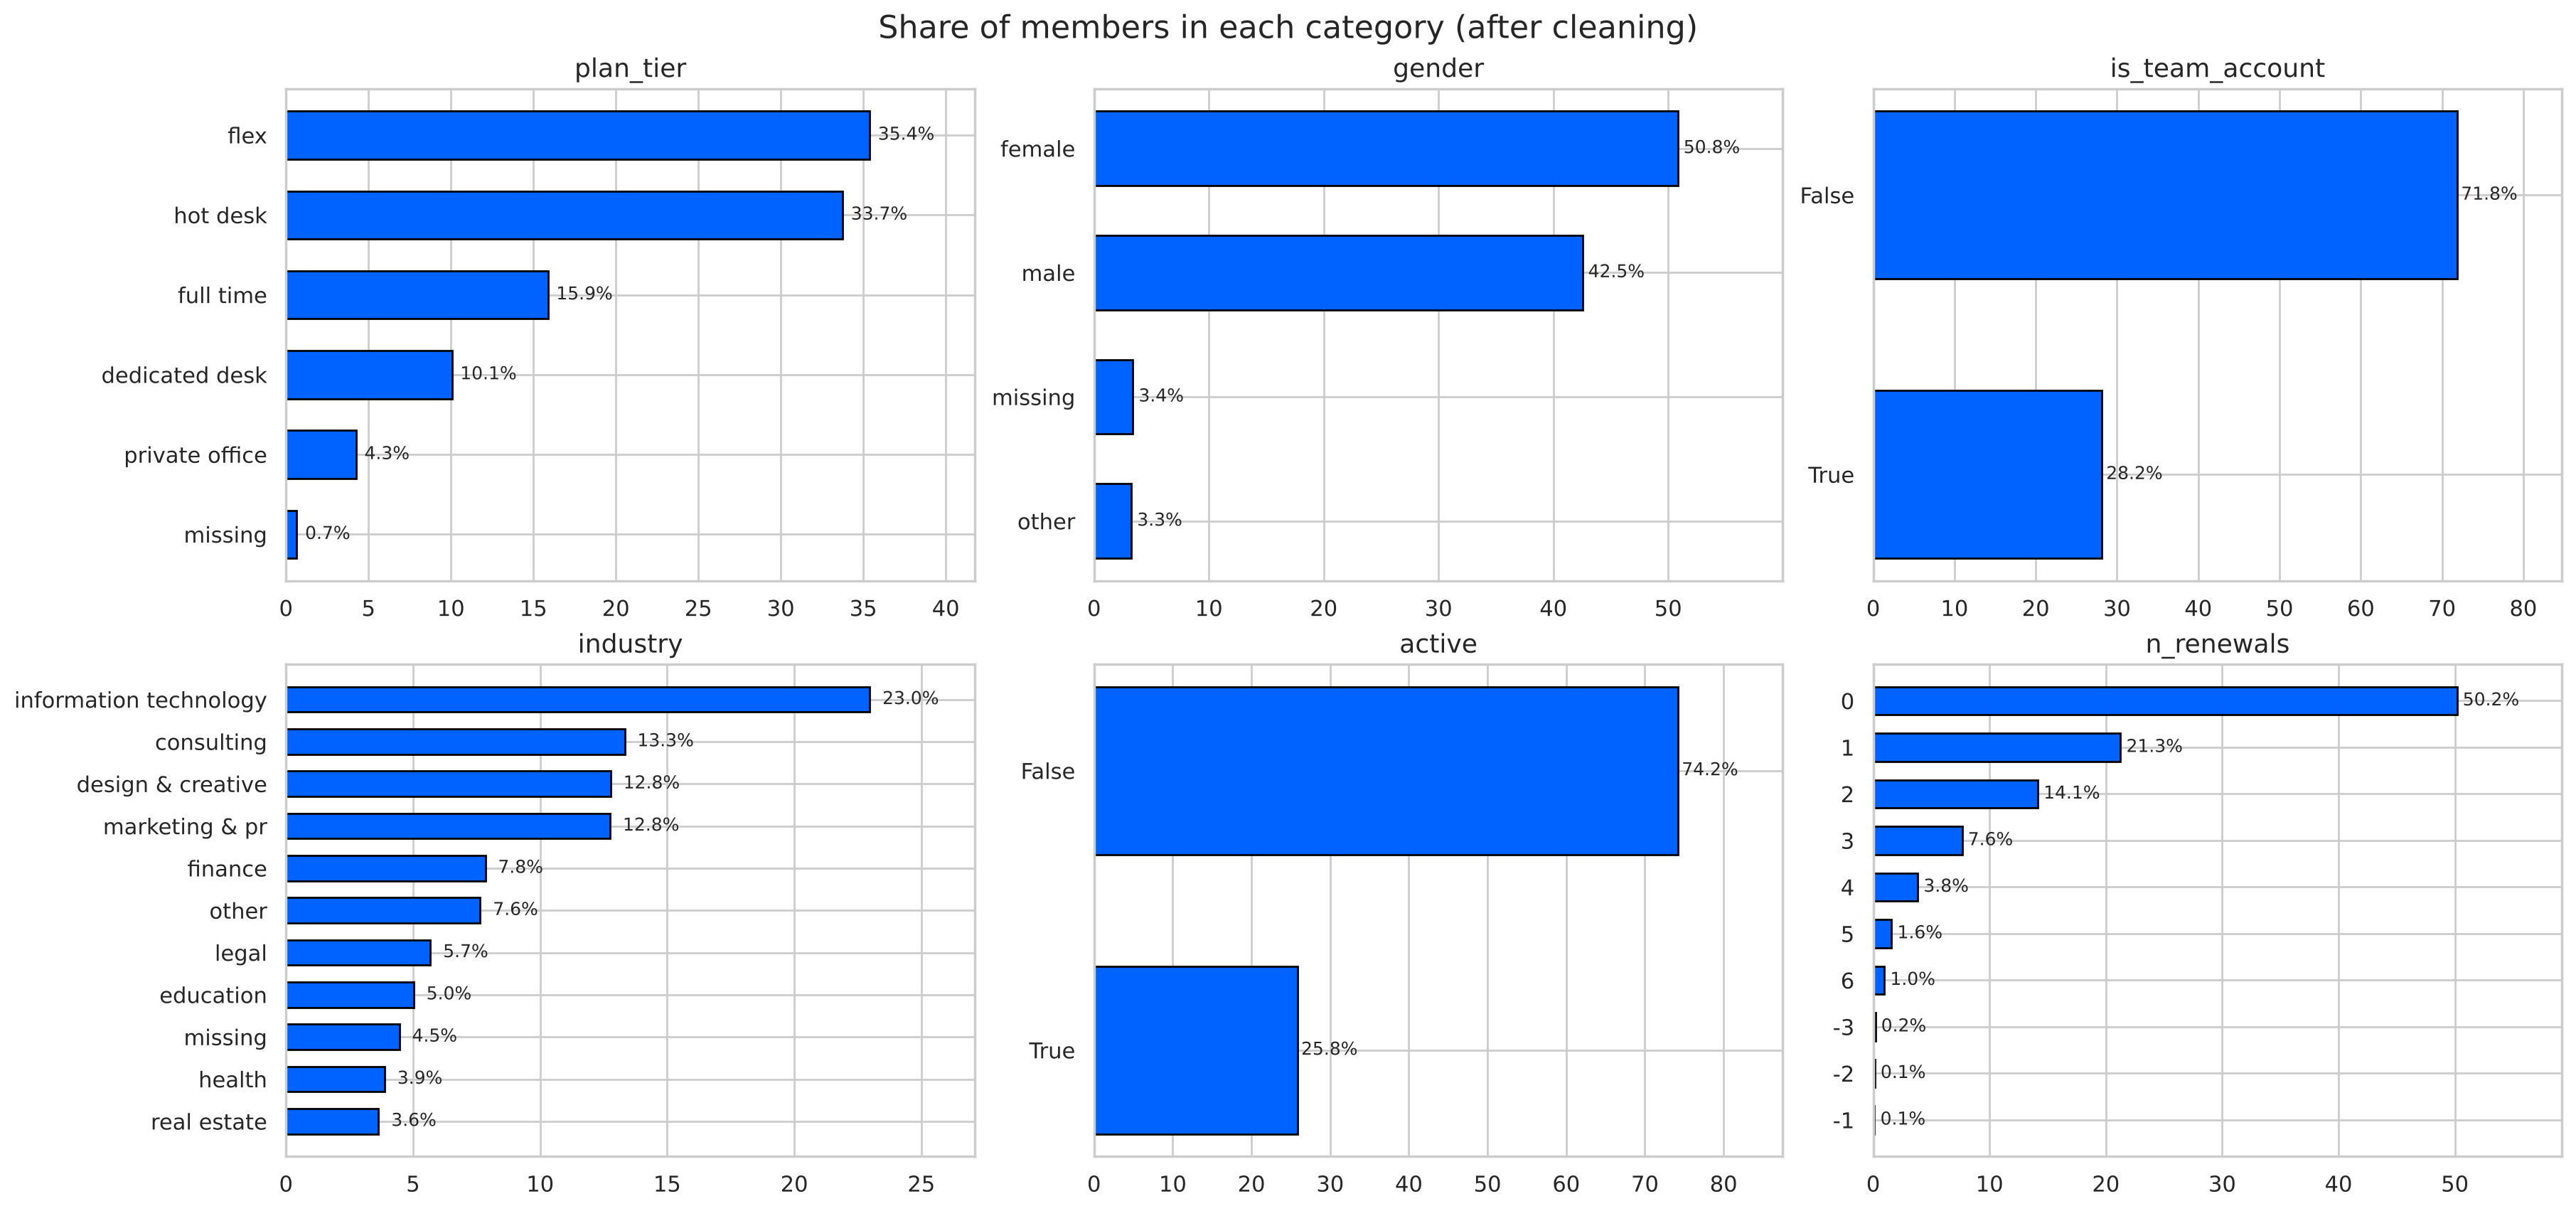

In [57]:
eda_after = chart_view(dataset)
plot_category_shares(eda_after, ["plan_tier", "gender", "is_team_account", "industry", "active", "n_renewals"],
                     "Share of members in each category (after cleaning)")

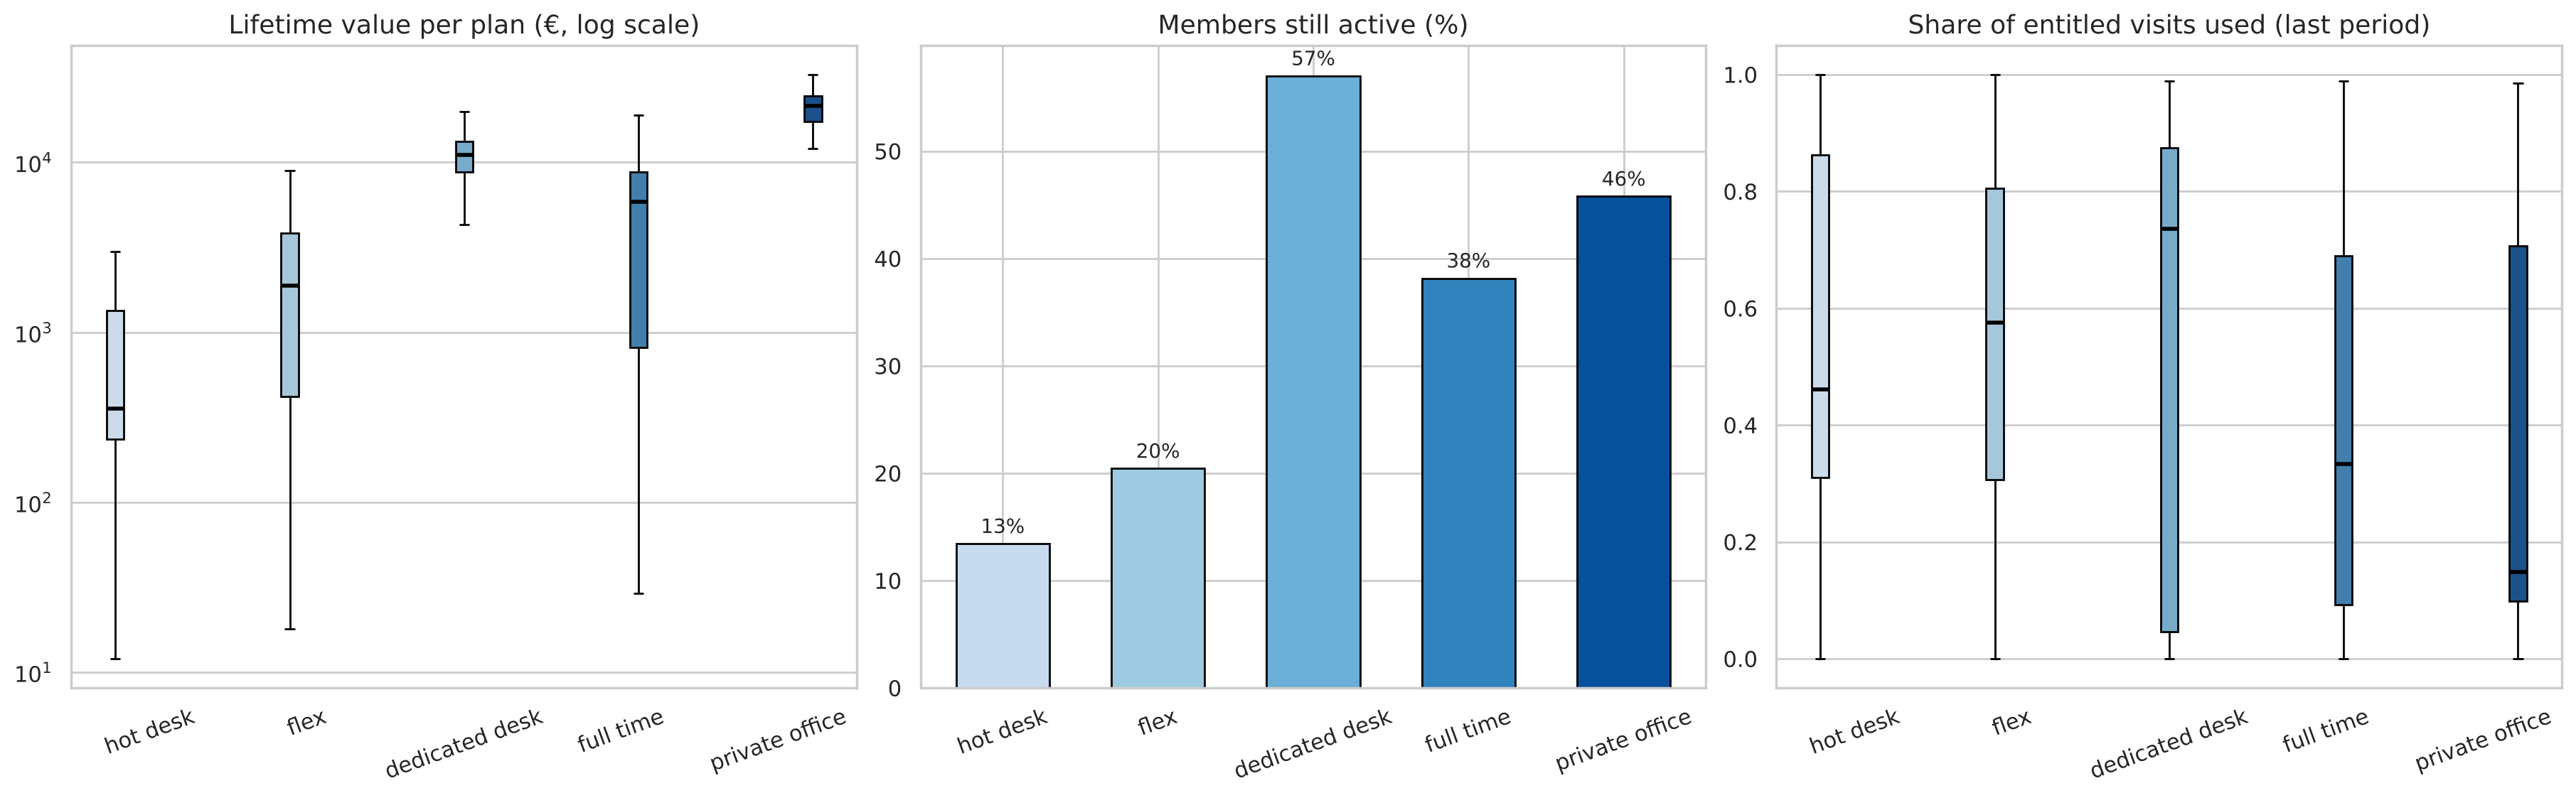

,members,median_lifetime_value,active_pct,median_utilisation,median_renewals
plan_tier,,,,,
hot desk,5078,355.47,13.43,0.46,0.0
flex,5325,1871.12,20.43,0.57,0.0
dedicated desk,1514,11037.38,57.00,0.74,2.0
full time,2390,5861.37,38.16,0.33,1.0
private office,640,21488.02,45.78,0.15,2.0


In [58]:
plot_plan_overview(eda_after)

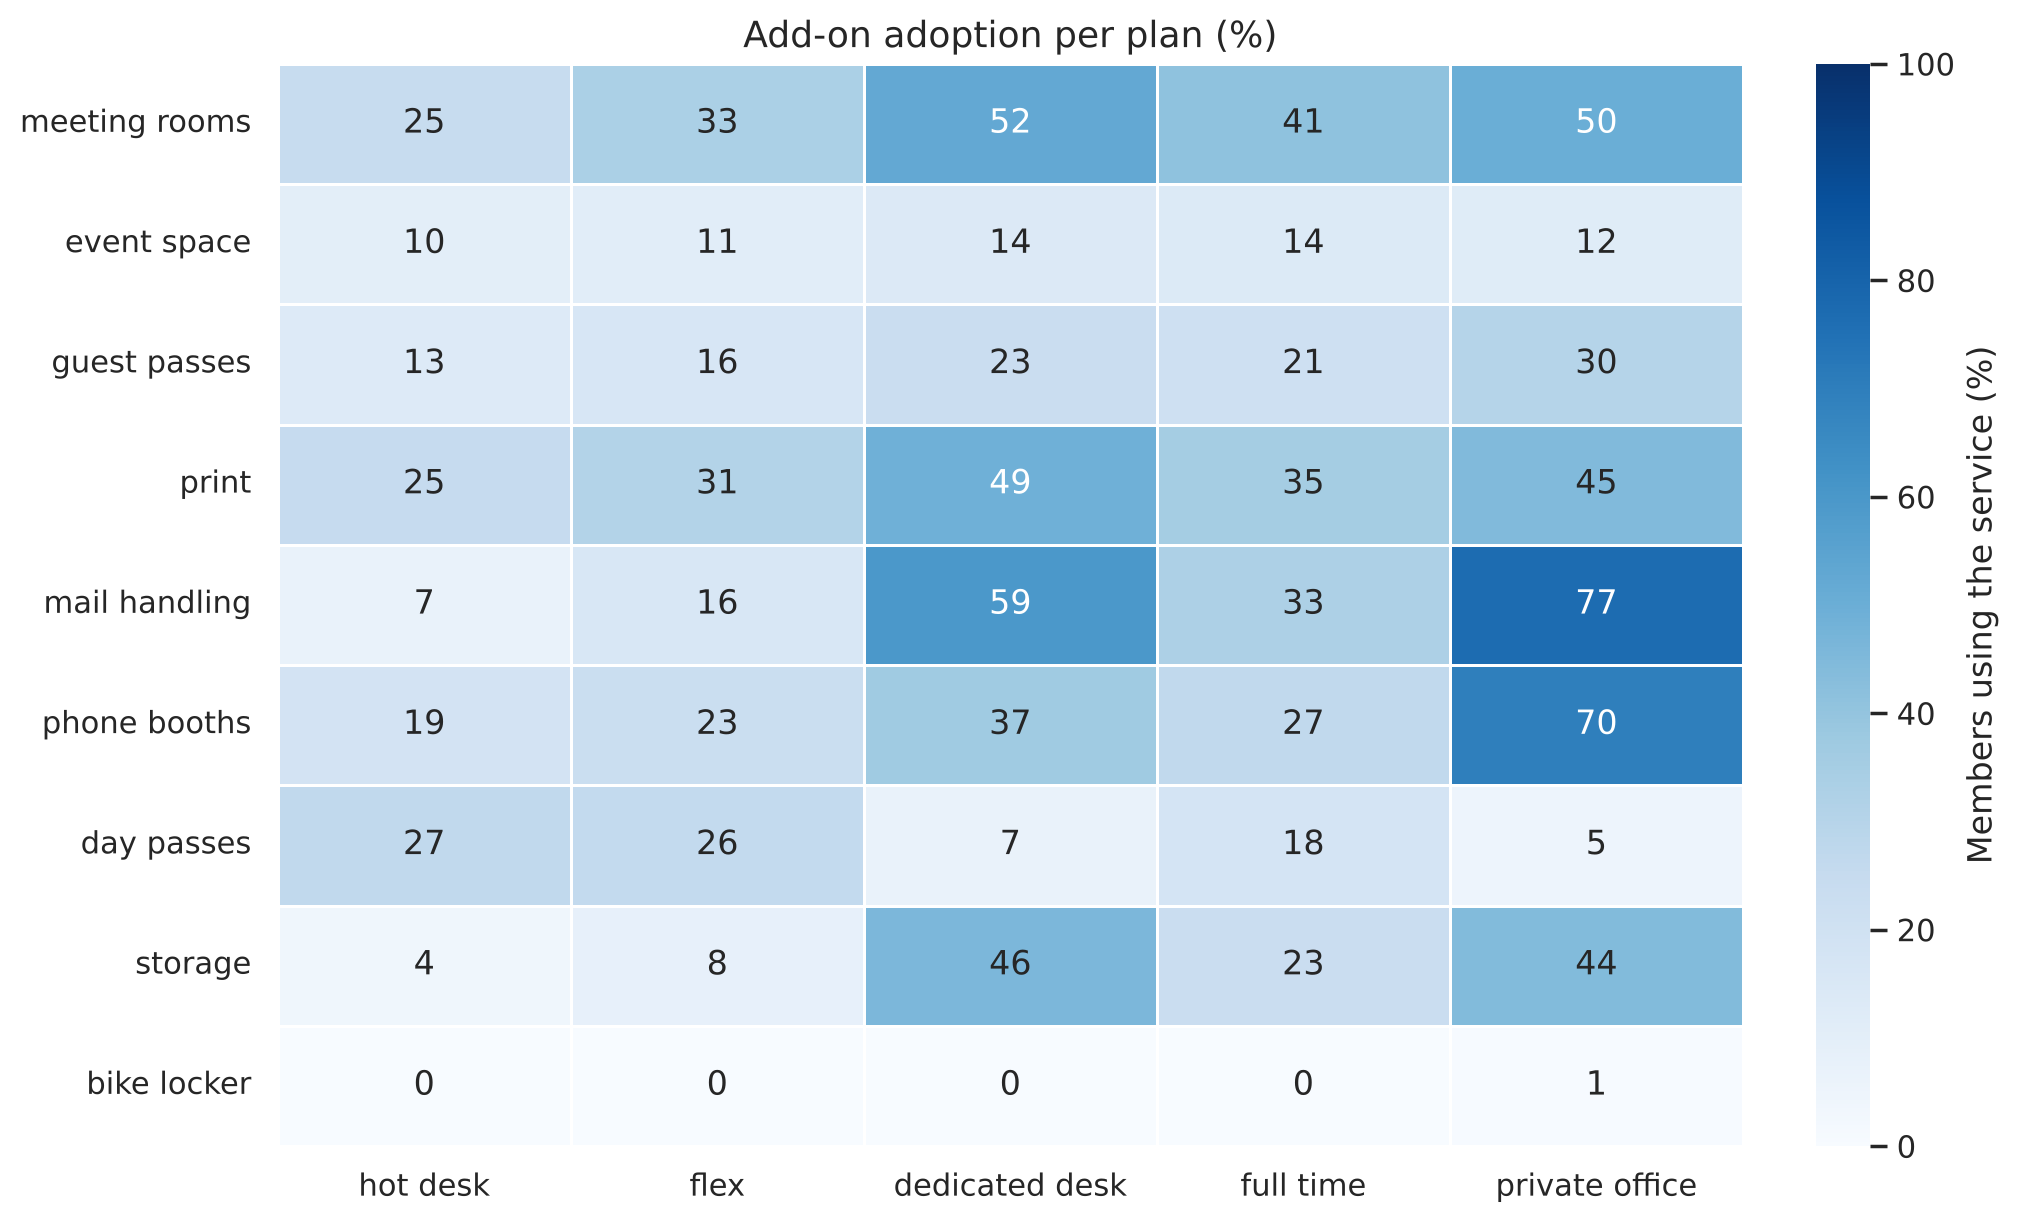

In [59]:
plot_addons_by_plan(eda_after)

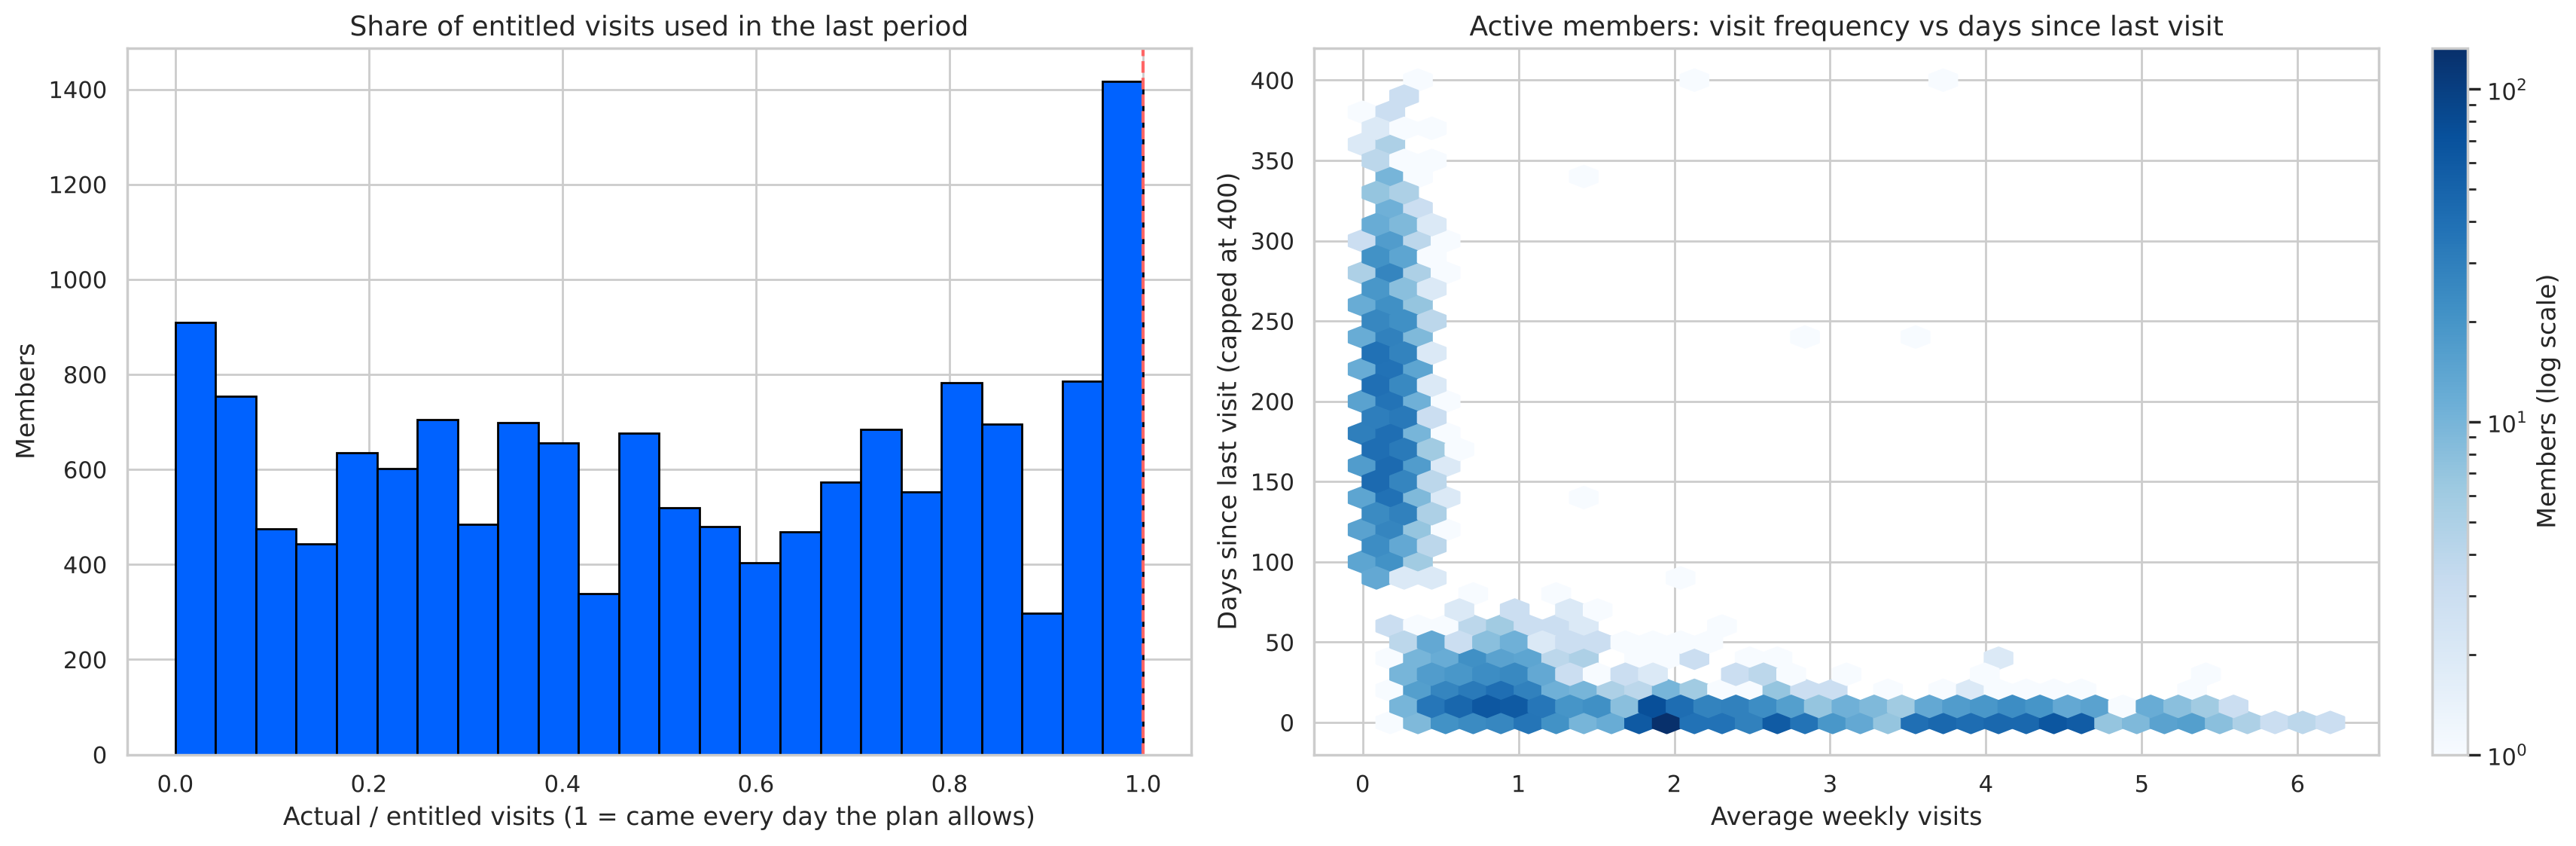

utilisation,below 20%,20-80%,above 80%
plan_tier,,,
hot desk,10.7,59.4,29.9
flex,15.0,58.8,26.2
dedicated desk,34.9,25.0,40.1
full time,34.3,51.7,14.0
private office,60.1,26.8,13.1


In [60]:
plot_usage_patterns(eda_after)

In [61]:
dormant_members(eda_after)

Active members: 3885  |  no visit for more than 90 days: 1281 (33%)


,% of dormant active members
plan_tier,
full time,39.3
dedicated desk,35.2
flex,25.5
hot desk,0.0
private office,0.0


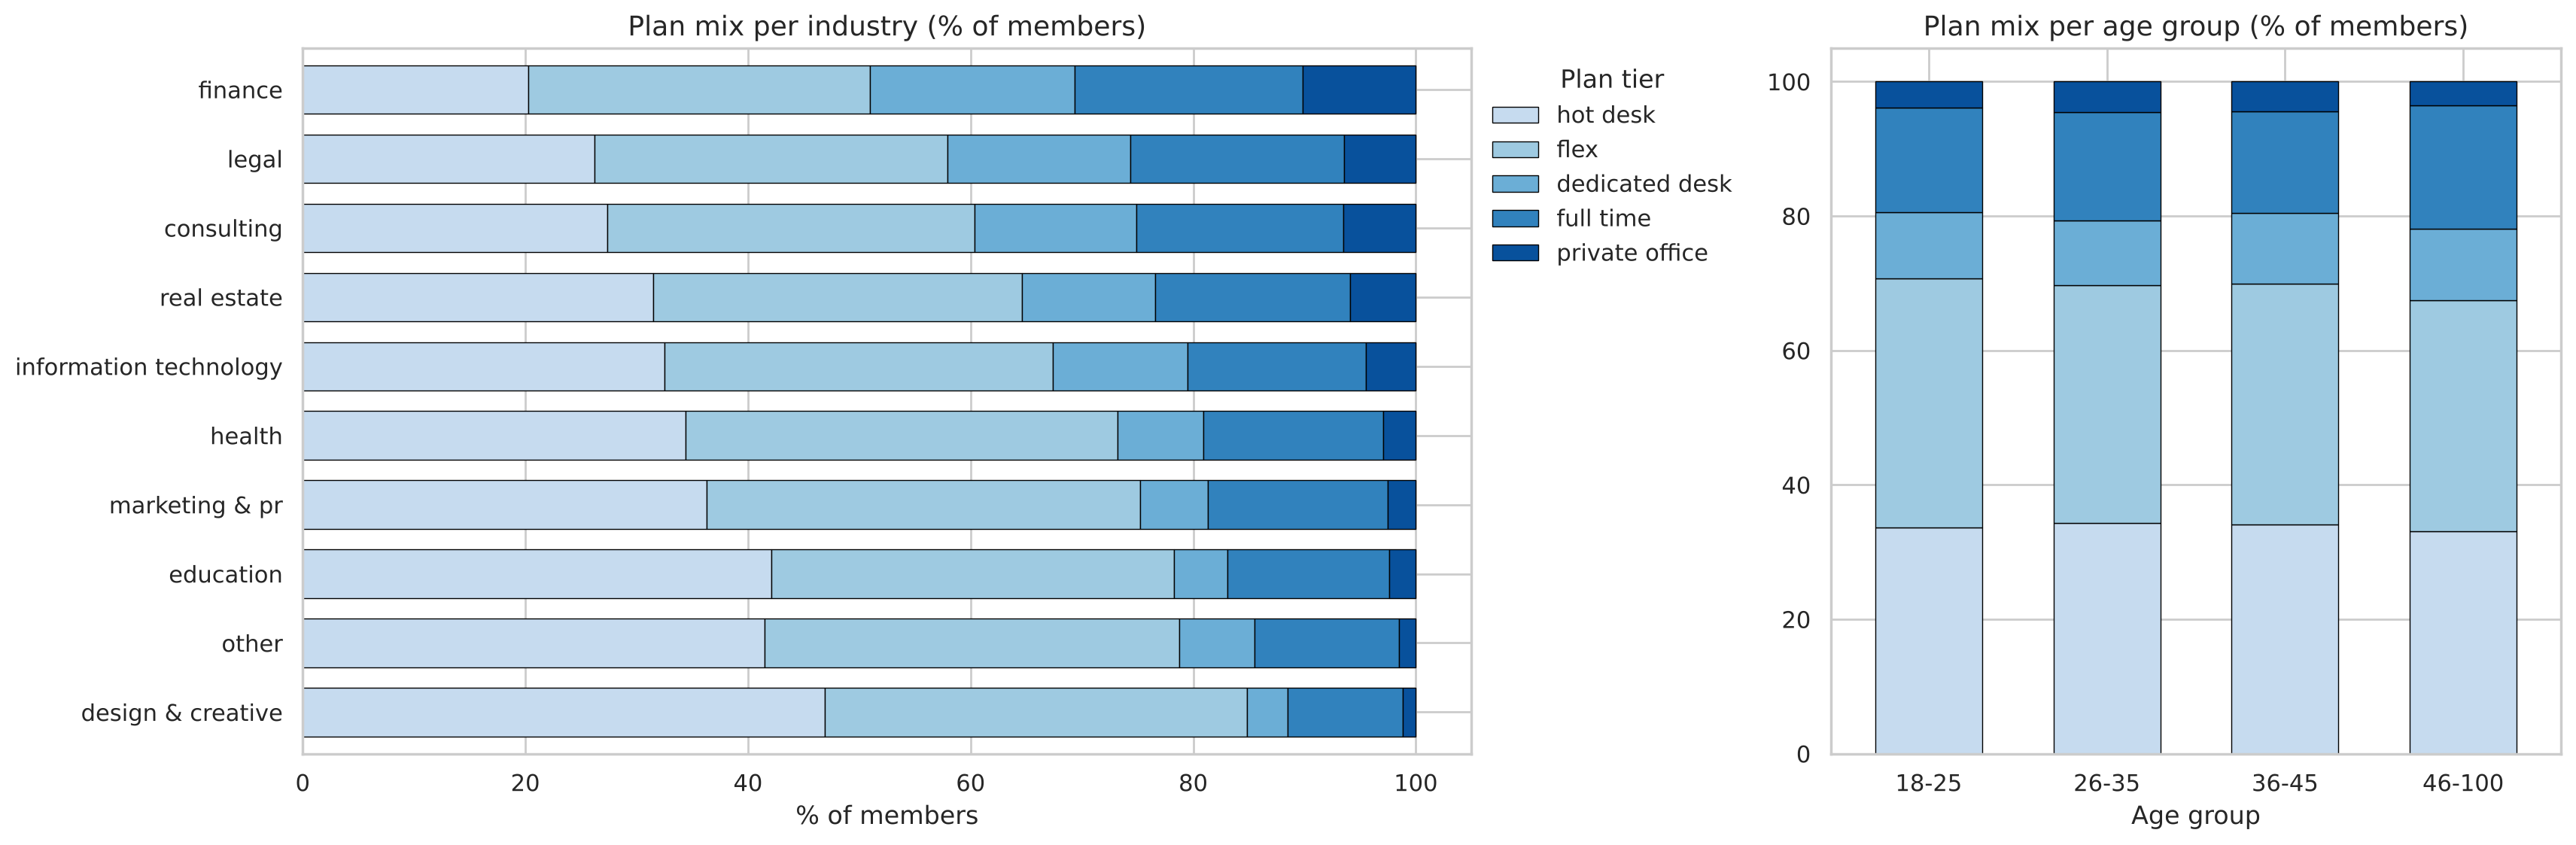

is_team_account,False,True
plan_tier,,
hot desk,71.9,28.1
flex,71.1,28.9
dedicated desk,72.5,27.5
full time,73.2,26.8
private office,68.6,31.4


In [62]:
plot_profile_vs_plan(eda_after)

After the cleaning the picture is practically the same as before. The plan medians, the share of active members and the utilisation groups change by less than one percentage point, and about one in three active members still has not visited in over 90 days. So the patterns we described were not caused by the errors in the data, which makes us more confident in using them for the segmentation.

## Correlation between Variables

In this section, we examine the relationships between numerical variables using a correlation matrix. This allows us to identify strong associations, potential redundancies, and patterns that may inform further analysis or feature selection.

We use **Spearman** correlation as our main measure. Pearson only captures straight-line relationships and can be dominated by a few extreme values, while Spearman is computed on the ranks of the values, so it measures whether two variables tend to increase (or decrease) together, regardless of the shape of the relationship or of extreme values. This suits our data, which is highly skewed, still contains extreme values and placeholders (e.g. `999` in `days_since_last_visit`), and includes ordered counts such as `plan_days_per_week` and `n_renewals`. Pearson is computed only to compare the two methods.

Note that `lifetime_value` is not included yet, as it is still stored as text, and that these correlations are computed before cleaning the data. They are therefore preliminary and will be revisited after the data cleaning step.

In [63]:
acdc_numeric_subset = dataset[[
    'age',
    'n_colleagues_on_account',
    'plan_days_per_week',
    'days_since_last_visit',
    'total_visits',
    'avg_weekly_visits',
    'entitled_visits_last_period',
    'actual_visits_last_period',
    'meeting_room_hours',
    'event_space_hours',
    'guest_passes_issued',
    'n_renewals'
]]

# Spearman is our main measure; Pearson is computed only for comparison
corr_spearman = acdc_numeric_subset.corr(method="spearman")
corr_pearson = acdc_numeric_subset.corr(method="pearson")

# Mask for the upper triangle and the diagonal (mirror image and self-correlations),
# so that each pair of variables appears only once
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

# Compare both methods for every pair of variables
corr_comparison = pd.DataFrame({
    "Pearson": corr_pearson.where(~mask).stack(),
    "Spearman": corr_spearman.where(~mask).stack()
})
corr_comparison["Difference"] = corr_comparison["Spearman"] - corr_comparison["Pearson"]

# Pairs where the two methods disagree the most
corr_comparison.sort_values("Difference", key=abs, ascending=False).head(10).round(2)

,,Pearson,Spearman,Difference
n_renewals,days_since_last_visit,0.11,-0.24,-0.34
meeting_room_hours,total_visits,0.06,0.39,0.34
total_visits,days_since_last_visit,-0.24,-0.57,-0.33
avg_weekly_visits,days_since_last_visit,-0.46,-0.73,-0.28
meeting_room_hours,actual_visits_last_period,0.04,0.32,0.28
actual_visits_last_period,days_since_last_visit,-0.42,-0.69,-0.27
event_space_hours,meeting_room_hours,0.05,0.32,0.27
meeting_room_hours,avg_weekly_visits,0.04,0.30,0.26
guest_passes_issued,meeting_room_hours,0.08,0.34,0.26
meeting_room_hours,days_since_last_visit,-0.03,-0.28,-0.25


Most of the pairs where the two methods disagree involve `days_since_last_visit` and `meeting_room_hours`, precisely the variables that contain placeholders (`999`) and extreme values (up to 41,220 hours). For example, Pearson suggests almost no relationship between `days_since_last_visit` and `avg_weekly_visits` (-0.14), while Spearman shows a strong negative one (-0.65): members who visit more often have fewer days since their last visit. Pearson also underestimates how similar `actual_visits_last_period` and `avg_weekly_visits` are (0.66 vs 0.93). This confirms that Pearson is distorted by these values in our raw data, so we rely on Spearman from here on.

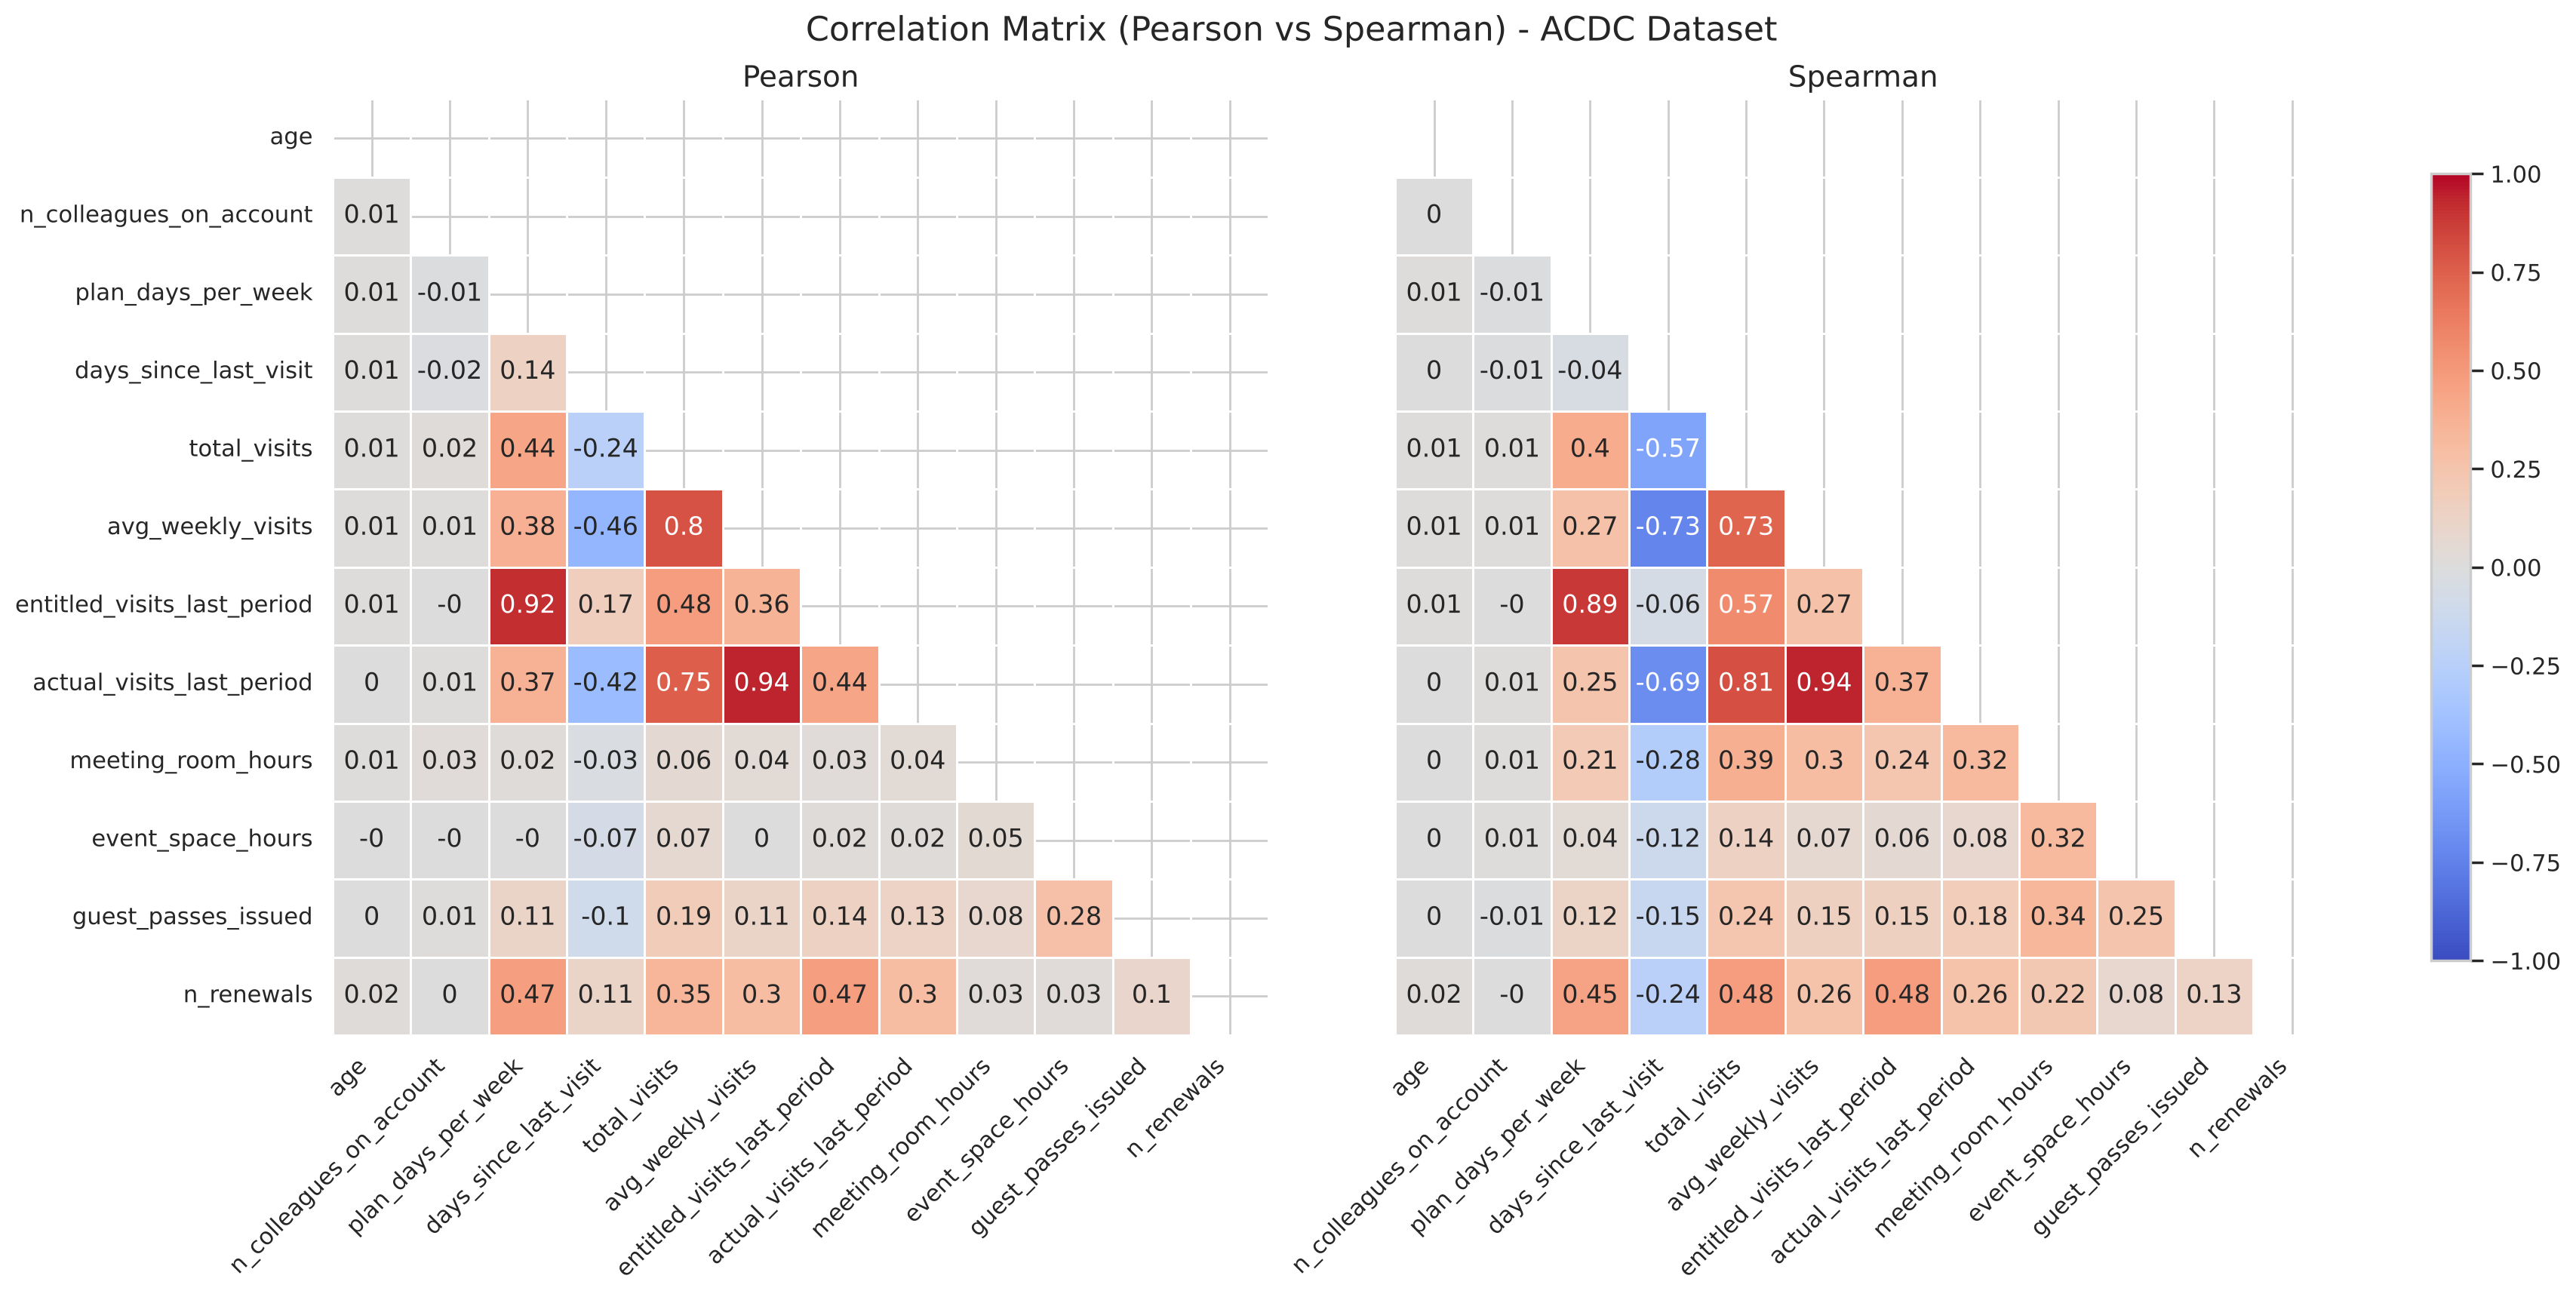

In [64]:
# Pearson (left) and Spearman (right) side by side, on the same colour scale
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5), layout="constrained")

for ax, corr, method in zip(axes, [corr_pearson, corr_spearman], ["Pearson", "Spearman"]):
    sns.heatmap(
        corr.round(2),
        mask=mask,                # hide the upper triangle and the diagonal
        annot=True,               # show the coefficient in each cell
        cmap="coolwarm",          # diverging palette: blue = negative, red = positive
        center=0,                 # centre the colour scale on 0
        linewidths=0.5,           # lines between cells
        vmin=-1, vmax=1,          # same fixed scale for both plots
        square=True,              # square cells
        cbar=False,               # a single shared colour bar is added below
        ax=ax
    )
    ax.set_title(method, fontsize=14)
    ax.tick_params(axis="x", labelrotation=45)
    plt.setp(ax.get_xticklabels(), ha="right")

# The rows are the same in both plots, so the variable names are only shown on the left
axes[1].set_yticks([])

# One colour bar shared by both heatmaps
fig.colorbar(axes[1].collections[0], ax=axes, shrink=0.8)

fig.suptitle("Correlation Matrix (Pearson vs Spearman) - ACDC Dataset", fontsize=16)
plt.show()

In [65]:
# Strongest relationships first, sorted by absolute value (positive or negative)
top_pairs = corr_spearman.where(~mask).stack().sort_values(key=abs, ascending=False)

top_pairs.head(10).round(2).to_frame("Spearman")

Spearman
actual_visits_last_period   avg_weekly_visits                0.94
entitled_visits_last_period plan_days_per_week               0.89
actual_visits_last_period   total_visits                     0.81
avg_weekly_visits           days_since_last_visit           -0.73
                            total_visits                     0.73
actual_visits_last_period   days_since_last_visit           -0.69
entitled_visits_last_period total_visits                     0.57
total_visits                days_since_last_visit           -0.57
n_renewals                  entitled_visits_last_period      0.48
                            total_visits                     0.48

**Conclusions from the correlation analysis:**

- Three pairs have a correlation of 0.8 or higher, meaning they carry almost the same information: `actual_visits_last_period` and `avg_weekly_visits` (0.93), `entitled_visits_last_period` and `plan_days_per_week` (0.88), and `actual_visits_last_period` and `total_visits` (0.80). Keeping both variables of a pair would give that behaviour double weight in the clustering, so one variable of each pair is a candidate to be dropped.
- The strong link between `entitled_visits_last_period` and `plan_days_per_week` supports our earlier hypothesis that the entitled visits are calculated from the plan rather than counted.
- Visit frequency is negatively related to `days_since_last_visit` (between -0.51 and -0.65): members who visit more often have fewer days since their last visit.
- `age` and `n_colleagues_on_account` are practically uncorrelated with all the other variables (|ρ| ≤ 0.02), so they bring independent information about the member's profile rather than their behaviour.